# Klimawandel in Daten erklärt

**Data Science II: Projekt**

**Adam und Farouk**

Ziel: Wir zeigen mit öffentlichen Daten, dass der Klimawandel messbar ist, woher die CO2-Emissionen kommen,
wer wie viel ausstößt und wie sich die Welt dadurch verändert. Das Notebook folgt der Gliederung unserer Präsentation.

**Gliederung**

| Kapitel | Inhalt |
|:---|:---|
| 0 | Einstieg: Treibhausgase |
| 1 | Gibt es den Klimawandel überhaupt? Temperatur und CO2 in Daten |
| 2 | Rückblick: Seit wann und warum steigen die Emissionen? |
| 3 | Globale Verteilung der CO2-Emissionen nach Ländern |
| 4 | Veränderung der Welt: Meeresspiegel, Meereis, Extremwetter, Krankheiten |

**Datenquellen:** Our World in Data (CO2, Bevölkerung, Verkehr, Sektoren), NASA GISTEMP (Temperatur),
NASA Sea Level, NSIDC Sea Ice Index, EM-DAT über Kaggle (Naturkatastrophen) und ein Kaggle-Datensatz zu
klimabedingten Krankheiten. Die Links stehen in der README.

---
# 0. Einstieg: Treibhausgase

Der Treibhauseffekt entsteht durch Gase, die die Wärmestrahlung der Erde zurückhalten. Den größten Anteil hat
CO2, deshalb konzentrieren wir uns im weiteren Verlauf auf CO2. Die Anteile in diesem Diagramm haben wir von Hand eingetragen.

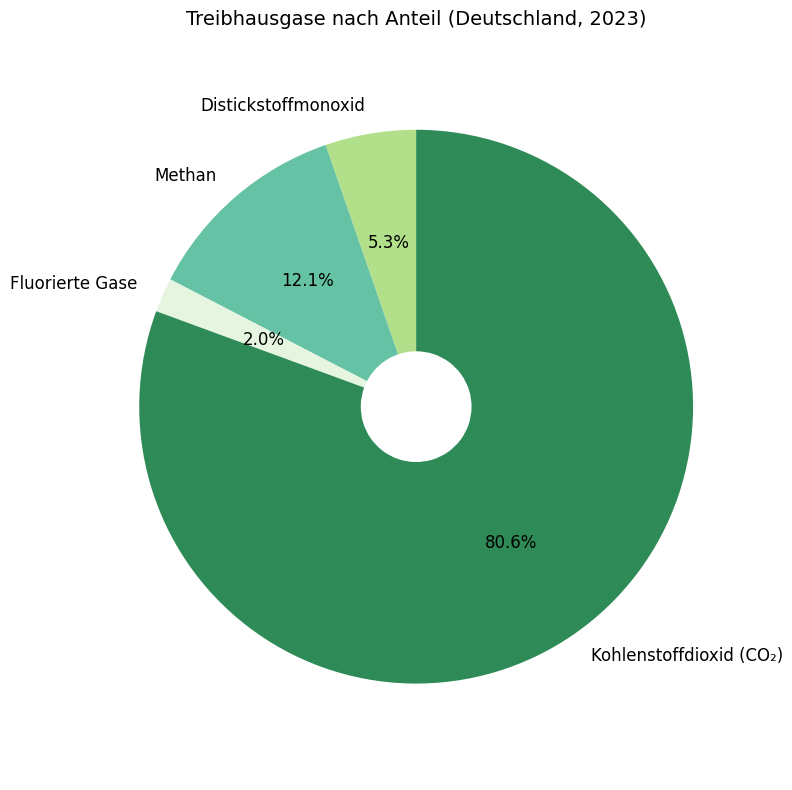

In [1]:
import matplotlib.pyplot as plt


labels = [ 'Distickstoffmonoxid', 'Methan','Fluorierte Gase', 'Kohlenstoffdioxid (CO₂)']
werte = [5.3, 12.1,2.0,  80.6]
farben = [ '#b2df8a', '#66c2a5','#e5f5e0', '#2e8b57']


fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    werte,
    labels=labels,
    colors=farben,
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 12, 'color': 'black'},
    wedgeprops={'width': 0.8} 
)

ax.axis('equal')
plt.title("Treibhausgase nach Anteil (Deutschland, 2023)", fontsize=14)
plt.tight_layout()
plt.show()


---
# 1. Gibt es den Klimawandel überhaupt?

**These: Der Klimawandel ist messbar und in Daten sichtbar.** Grundlage sind die Temperaturdaten der NASA (GISTEMP).
Gezeigt wird jeweils die Abweichung vom Mittel der Jahre 1951 bis 1980.

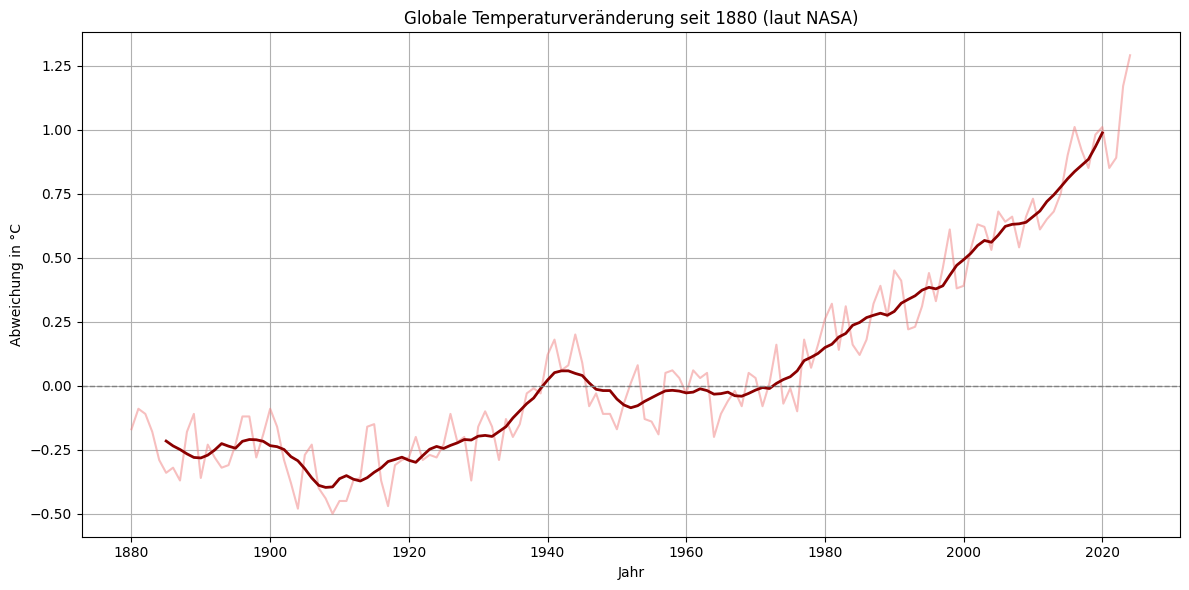

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("nasa_tempeture.csv", skiprows=1)

df.rename(columns={df.columns[0]: 'Year'}, inplace=True)
df = df[['Year', 'J-D']].dropna()
df['J-D'] = pd.to_numeric(df['J-D'], errors='coerce')

df['Glättung'] = df['J-D'].rolling(window=10, center=True).mean()

plt.figure(figsize=(12, 6))
plt.plot(df['Year'], df['J-D'], color='lightcoral', alpha=0.5)
plt.plot(df['Year'], df['Glättung'], color='darkred', linewidth=2)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)

plt.title('Globale Temperaturveränderung seit 1880 (laut NASA)')
plt.xlabel('Jahr')
plt.ylabel('Abweichung in °C')

plt.grid(True)
plt.tight_layout()
plt.show()


Seit etwa 1980 steigt die globale Temperatur fast ohne Unterbrechung. Inzwischen liegt sie rund ein Grad über dem Mittel von 1951 bis 1980.

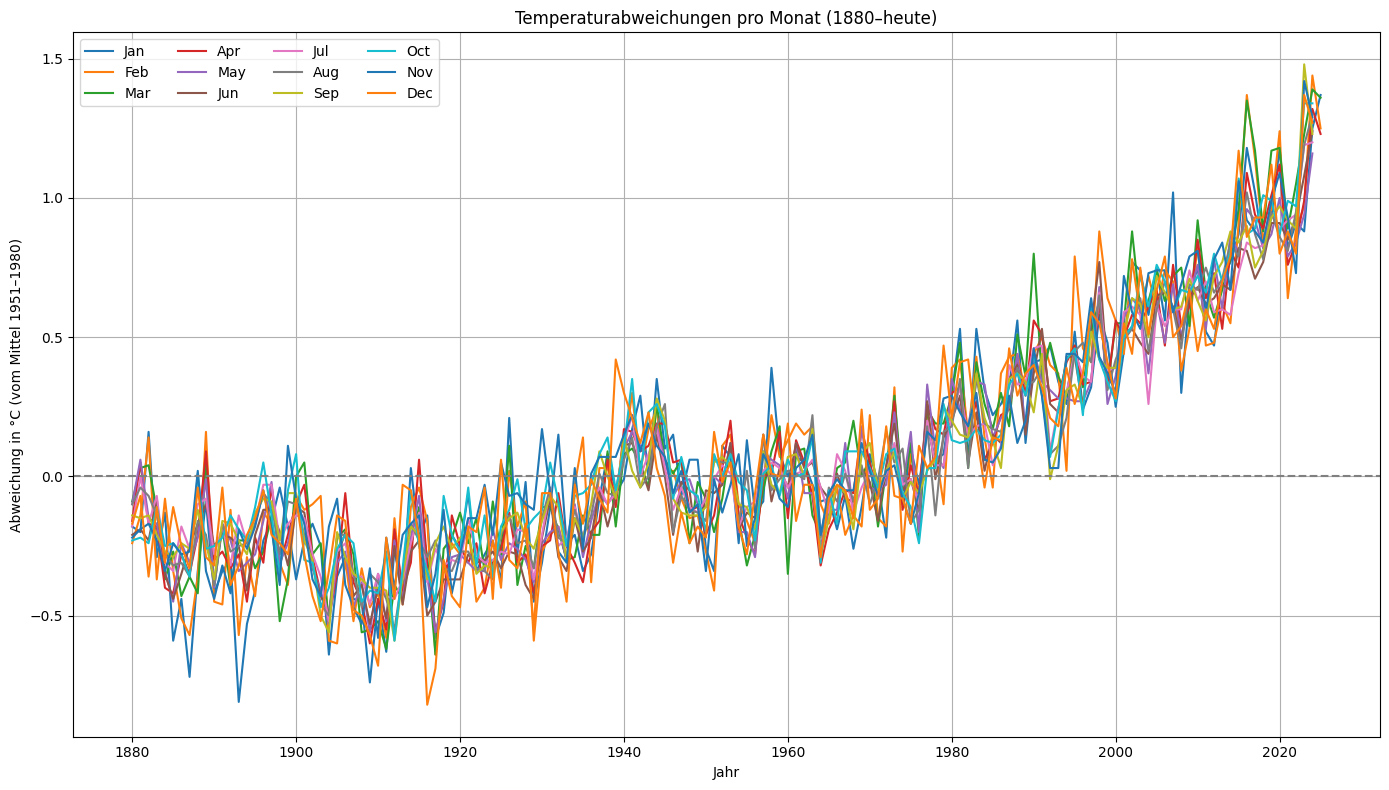

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("nasa_tempeture.csv", skiprows=1)

df.rename(columns={df.columns[0]: 'Year'}, inplace=True)

monate = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

df_monate = df[['Year'] + monate].dropna()

for monat in monate:
    df_monate[monat] = pd.to_numeric(df_monate[monat], errors='coerce')

plt.figure(figsize=(14, 8))

for monat in monate:
    plt.plot(df_monate['Year'], df_monate[monat], label=monat)

plt.axhline(0, color='gray', linestyle='--')
plt.title("Temperaturabweichungen pro Monat (1880–heute)")
plt.xlabel("Jahr")
plt.ylabel("Abweichung in °C (vom Mittel 1951–1980)")
plt.legend(ncol=4, loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()


Der Anstieg betrifft nicht nur einzelne Jahreszeiten: Alle zwölf Monate folgen demselben Trend.

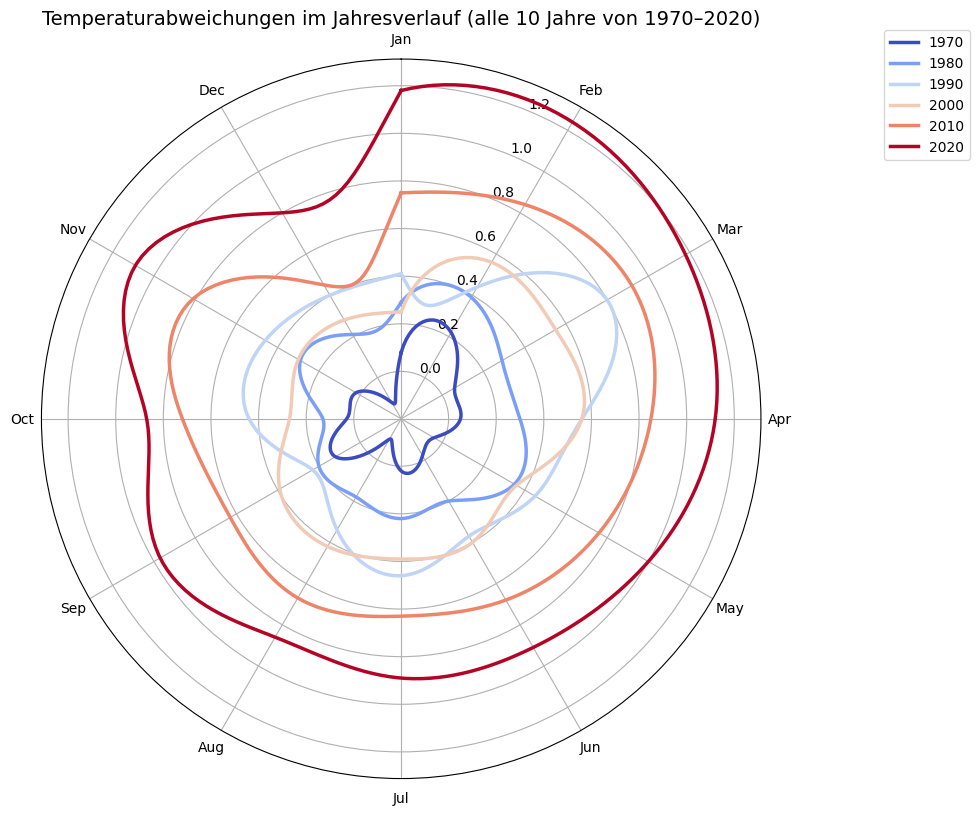

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

df = pd.read_csv("nasa_tempeture.csv", skiprows=1)
df.rename(columns={df.columns[0]: 'Year'}, inplace=True)

monate = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

df_monate = df[['Year'] + monate].dropna()
for monat in monate:
    df_monate[monat] = pd.to_numeric(df_monate[monat], errors='coerce')

jahre = list(range(1970, 2021, 10))
df_auswahl = df_monate[df_monate['Year'].isin(jahre)]

winkel = np.linspace(0, 2 * np.pi, len(monate) + 1)

farben = plt.cm.coolwarm(np.linspace(0, 1, len(jahre)))

plt.figure(figsize=(10, 10))
ax = plt.subplot(111, polar=True)

for i, jahr in enumerate(jahre):
    werte = df_auswahl[df_auswahl['Year'] == jahr][monate].values.flatten()
    werte = np.append(werte, werte[0])

    winkel_fine = np.linspace(winkel.min(), winkel.max(), 200)
    spline = make_interp_spline(winkel, werte, k=3)
    werte_glatt = spline(winkel_fine)

    ax.plot(winkel_fine, werte_glatt, label=str(jahr), color=farben[i], linewidth=2.5)

ax.set_theta_direction(-1)
ax.set_theta_offset(np.pi / 2)
ax.set_xticks(np.linspace(0, 2 * np.pi, 12, endpoint=False))
ax.set_xticklabels(monate)
ax.set_title("Temperaturabweichungen im Jahresverlauf (alle 10 Jahre von 1970–2020)", fontsize=14)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.05))
plt.tight_layout()
plt.show()


Im Polardiagramm wird das noch deutlicher: Jeder Ring ist ein Jahrzehnt. Die Kurven wandern von 1970 bis 2020
Jahrzehnt für Jahrzehnt nach außen, also wird jeder Monat wärmer.

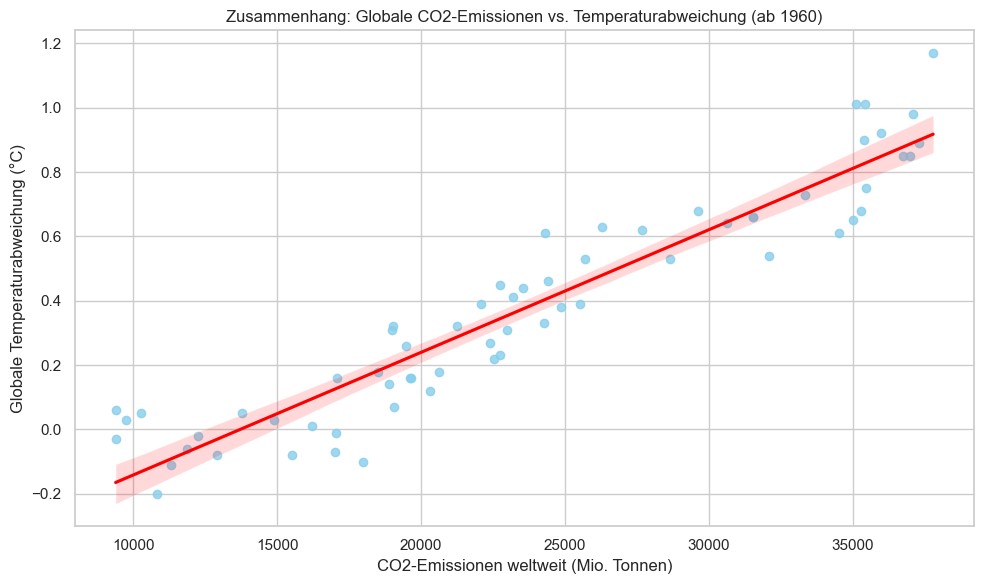

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_co2 = pd.read_csv("owid-co2-data.csv")
df_world = df_co2[(df_co2['country'] == 'World') & (df_co2['year'] >= 1960)][['year', 'co2']].dropna()

df_temp = pd.read_csv("nasa_tempeture.csv", skiprows=1)
df_temp.rename(columns={df_temp.columns[0]: 'year'}, inplace=True)
df_temp = df_temp[['year', 'J-D']].dropna()
df_temp['J-D'] = pd.to_numeric(df_temp['J-D'], errors='coerce')
df_temp = df_temp[df_temp['year'] >= 1960]

df = pd.merge(df_world, df_temp, on='year')

plt.figure(figsize=(10, 6))
sns.set(style="whitegrid")

sns.regplot(data=df, x='co2', y='J-D', scatter_kws={"color": "skyblue"}, line_kws={"color": "red", "label": "Lineare Regression"})

plt.title('Zusammenhang: Globale CO2-Emissionen vs. Temperaturabweichung (ab 1960)')
plt.xlabel('CO2-Emissionen weltweit (Mio. Tonnen)')
plt.ylabel('Globale Temperaturabweichung (°C)')
plt.tight_layout()
plt.show()

Seit 1960 hängen die weltweiten CO2-Emissionen und die Temperaturabweichung eng zusammen. Die Regressionsgerade
zeigt einen klaren positiven Zusammenhang. Eine Korrelation allein beweist noch keine Ursache, sie passt aber zum
physikalisch gut belegten Treibhauseffekt aus Kapitel 0.

---
# 2. Rückblick: Seit wann und warum?

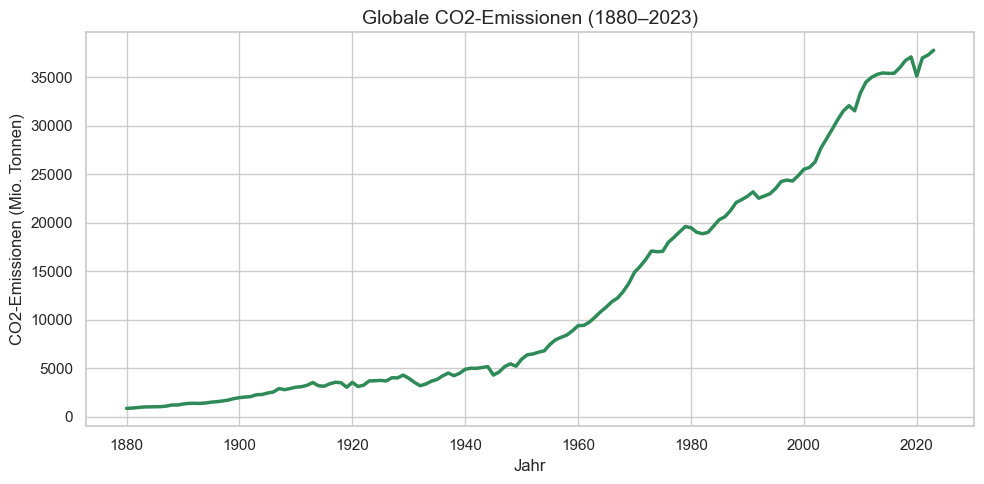

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("owid-co2-data.csv")

df_world = df[
    (df['country'] == 'World') &
    (df['year'] >= 1880) &
    (df['year'] <= 2023) &
    (df['co2'].notna())
]

plt.figure(figsize=(10, 5))
plt.plot(df_world['year'], df_world['co2'], color='#2e8b57', linewidth=2.5)
plt.grid(True)
plt.title('Globale CO2-Emissionen (1880–2023)', fontsize=14)
plt.xlabel('Jahr')
plt.ylabel('CO2-Emissionen (Mio. Tonnen)')
plt.tight_layout()
plt.show()

Bis etwa 1950 steigen die Emissionen langsam, danach rasant. Die folgenden Diagramme gehen den Gründen nach:
Wirtschaftswachstum und Industrialisierung, Bevölkerungswachstum und die Explosion des Verkehrs.

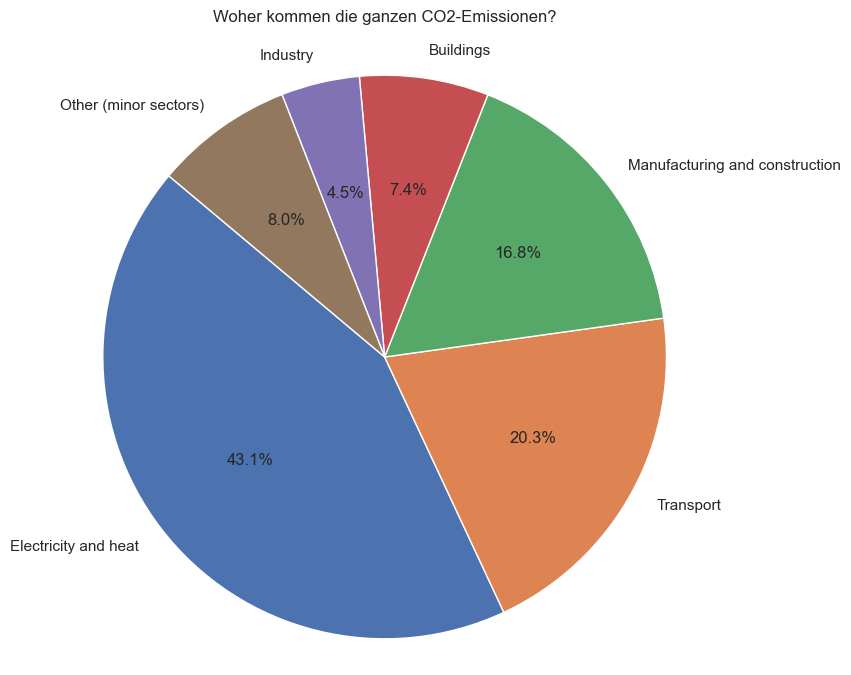

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("co-emissions-by-sector.csv")

df_world_2021 = df[(df["Entity"] == "World") & (df["Year"] == 2021)]

sectors = {
    "Electricity and heat": "Carbon dioxide emissions from electricity and heat",
    "Transport": "Carbon dioxide emissions from transport",
    "Manufacturing and construction": "Carbon dioxide emissions from manufacturing and construction",
    "Buildings": "Carbon dioxide emissions from buildings",
    "Industry": "Carbon dioxide emissions from industry",
    "Land-use change and forestry": "Carbon dioxide emissions from land use change and forestry",
    "Aviation and shipping": "Carbon dioxide emissions from bunker fuels",
    "Other fuel combustion": "Carbon dioxide emissions from other fuel combustion",
    "Fugitive emissions": "Fugitive emissions of carbon dioxide from energy production"
}

emissions_2021 = df_world_2021[list(sectors.values())].iloc[0]
emissions_2021.index = sectors.keys()
emissions_2021 = emissions_2021.dropna()

small_categories = [
    "Fugitive emissions",
    "Other fuel combustion",
    "Aviation and shipping",
    "Land-use change and forestry"
]

emissions_aggregated = emissions_2021.drop(labels=small_categories)
emissions_aggregated["Other (minor sectors)"] = emissions_2021[small_categories].sum()

plt.figure(figsize=(8, 8))
plt.pie(emissions_aggregated, labels=emissions_aggregated.index, autopct='%1.1f%%', startangle=140)
plt.title('Woher kommen die ganzen CO2-Emissionen?', pad=20)
plt.axis('equal')
plt.show()


Den größten Anteil haben Strom und Wärme, gefolgt von Verkehr sowie Industrie und Bau. Fast alles davon beruht auf
fossilen Energien wie Kohle, Öl und Erdgas.

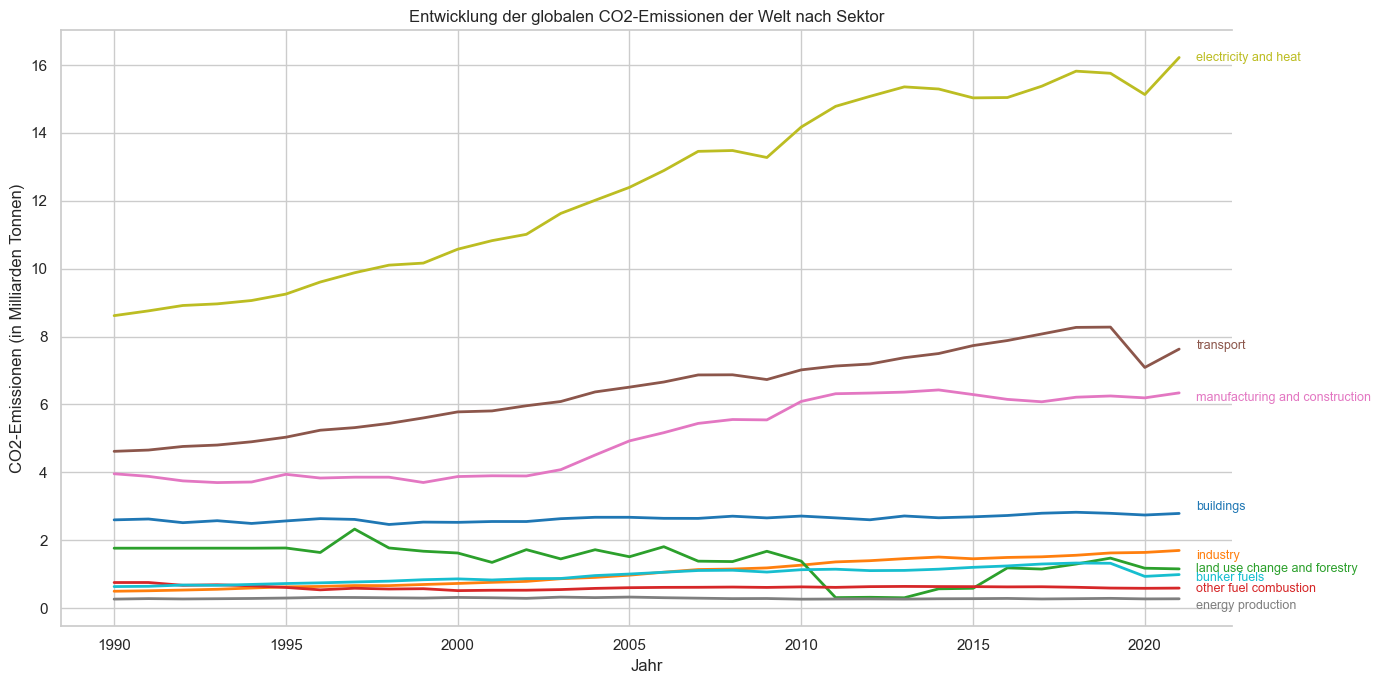

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

df = pd.read_csv("co-emissions-by-sector.csv")

df_world = df[df["Entity"] == "World"].sort_values("Year")

emission_cols = [col for col in df.columns if "Carbon dioxide emissions" in col or "Fugitive emissions" in col]

plt.figure(figsize=(14, 7))
colors = cm.tab10(np.linspace(0, 1, len(emission_cols)))
last_values = {}

for i, (col, color) in enumerate(zip(emission_cols, colors)):
    if df_world[col].notna().any():
        label = col.replace("Carbon dioxide emissions from ", "").replace("Fugitive emissions of carbon dioxide from ", "")
        plt.plot(df_world["Year"], df_world[col] / 1e9, color=color, linewidth=2)
        last_values[label] = {
            "x": df_world["Year"].values[-1],
            "y": df_world[col].values[-1] / 1e9, 
            "color": color,
            "offset": 0
        }

custom_offsets = {
    "electricity and heat": 0,
    "transport": 0.1,
    "manufacturing and construction": -0.15,
    "buildings": 0.2,
    "industry": -0.15,
    "land use change and forestry": 0,
    "bunker fuels": -0.1,
    "other fuel combustion": -0.03,
    "energy production": -0.2
}

for label in last_values:
    if label in custom_offsets:
        last_values[label]["offset"] = custom_offsets[label]

for label, info in last_values.items():
    plt.text(info["x"] + 0.5, info["y"] + info["offset"], label,
             fontsize=9, color=info["color"], va='center')

plt.title("Entwicklung der globalen CO2-Emissionen der Welt nach Sektor")
plt.xlabel("Jahr")
plt.ylabel("CO2-Emissionen (in Milliarden Tonnen)")
plt.grid(True)
plt.tight_layout()
plt.gca().spines['right'].set_visible(False)
plt.show()

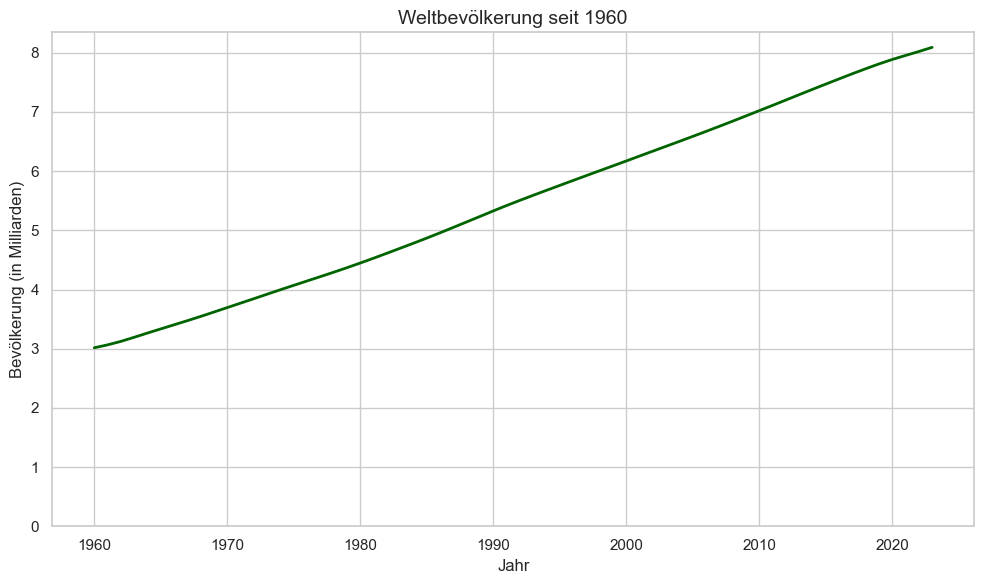

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("population.csv")

df_world = df[(df["Entity"] == "World") & (df["Year"] >= 1960)]

plt.figure(figsize=(10, 6))
plt.plot(df_world["Year"], df_world["Population (historical)"] / 1e9,
         color='darkgreen', linewidth=2)

plt.title("Weltbevölkerung seit 1960", fontsize=14)
plt.xlabel("Jahr")
plt.ylabel("Bevölkerung (in Milliarden)")
plt.ylim(0)
plt.grid(True)
plt.tight_layout()
plt.show()

Seit 1960 hat sich die Weltbevölkerung mehr als verdoppelt. Mehr Menschen bedeuten mehr Konsum, mehr Energieverbrauch
und damit mehr CO2.

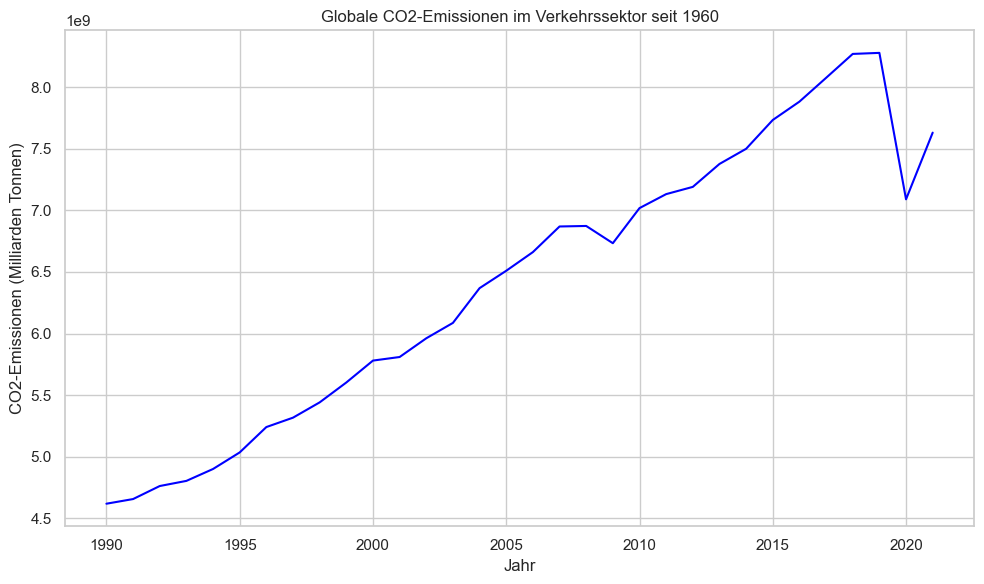

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('co2-emissions-transport.csv')

df_world = df[(df['Entity'] == 'World') & (df['Year'] >= 1960)]

plt.figure(figsize=(10, 6))
plt.plot(df_world['Year'], df_world['Carbon dioxide emissions from transport'], label='Verkehr', color='blue')
plt.title('Globale CO2-Emissionen im Verkehrssektor seit 1960')
plt.xlabel('Jahr')
plt.ylabel('CO2-Emissionen (Milliarden Tonnen)')
plt.grid(True)
plt.tight_layout()
plt.show()


Auch der Verkehr wächst stetig. Der Einbruch 2020 ist die Corona-Pandemie, danach steigen die Emissionen wieder.

---
# 3. Globale Verteilung der CO2-Emissionen nach Ländern

Nicht alle Länder sind gleich verantwortlich. Wir vergleichen die Gesamtemissionen mit den Emissionen pro Kopf.

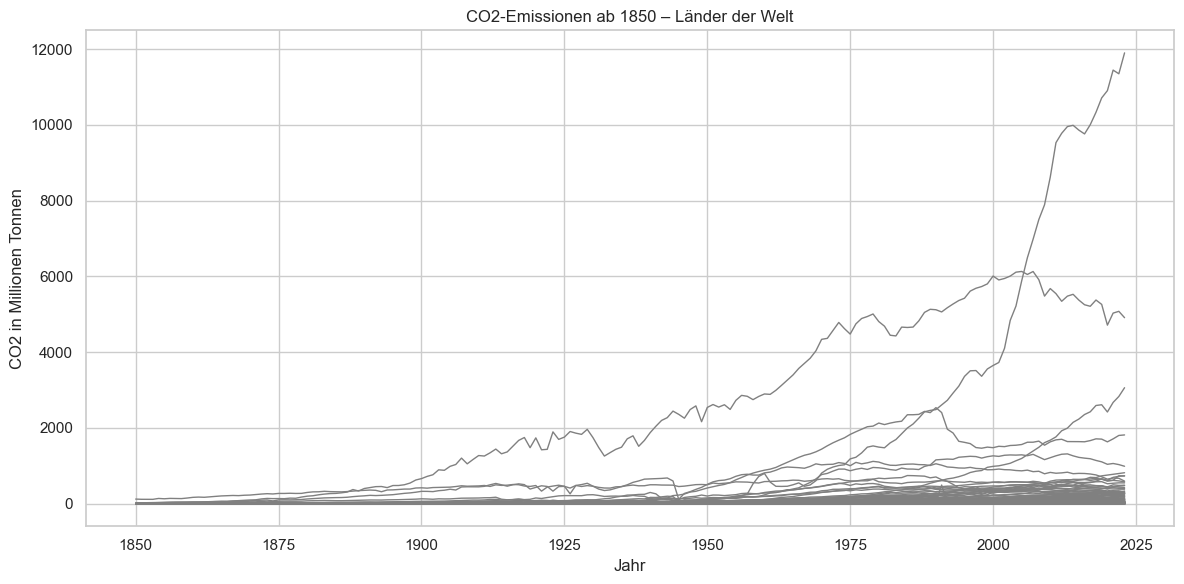

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("owid-co2-data.csv")

laender = ["Afghanistan", "Albania", "Algeria", "Andorra", "Angola", "Antigua and Barbuda", "Argentina", "Armenia", "Australia", "Austria", "Azerbaijan", "Bahamas", "Bahrain", "Bangladesh", "Barbados", "Belarus", "Belgium", "Belize", "Benin", "Bhutan", "Bolivia", "Bosnia and Herzegovina", "Botswana", "Brazil", "Brunei", "Bulgaria", "Burkina Faso", "Burundi", "Cambodia", "Cameroon", "Canada", "Cape Verde", "Central African Republic", "Chad", "Chile", "China", "Colombia", "Comoros", "Congo", "Costa Rica", "Cote d'Ivoire", "Croatia", "Cuba", "Cyprus", "Czechia", "Democratic Republic of Congo", "Denmark", "Djibouti", "Dominica", "Dominican Republic", "East Timor", "Ecuador", "Egypt", "El Salvador", "Equatorial Guinea", "Eritrea", "Estonia", "Eswatini", "Ethiopia", "Fiji", "Finland", "France", "Gabon", "Gambia", "Georgia", "Germany", "Ghana", "Greece", "Grenada", "Guatemala", "Guinea", "Guinea-Bissau", "Guyana", "Haiti", "Honduras", "Hungary", "Iceland", "India", "Indonesia", "Iran", "Iraq", "Ireland", "Israel", "Italy", "Jamaica", "Japan", "Jordan", "Kazakhstan", "Kenya", "Kiribati", "Kosovo", "Kuwait", "Kyrgyzstan", "Laos", "Latvia", "Lebanon", "Lesotho", "Liberia", "Libya", "Liechtenstein", "Lithuania", "Luxembourg", "Madagascar", "Malawi", "Malaysia", "Maldives", "Mali", "Malta", "Marshall Islands", "Mauritania", "Mauritius", "Mexico", "Micronesia (country)", "Moldova", "Monaco", "Mongolia", "Montenegro", "Morocco", "Mozambique", "Myanmar", "Namibia", "Nauru", "Nepal", "Netherlands", "New Zealand", "Nicaragua", "Niger", "Nigeria", "North Korea", "North Macedonia", "Norway", "Oman", "Pakistan", "Palau", "Palestine", "Panama", "Papua New Guinea", "Paraguay", "Peru", "Philippines", "Poland", "Portugal", "Qatar", "Romania", "Russia", "Rwanda", "Saint Kitts and Nevis", "Saint Lucia", "Saint Vincent and the Grenadines", "Samoa", "San Marino", "Sao Tome and Principe", "Saudi Arabia", "Senegal", "Serbia", "Seychelles", "Sierra Leone", "Singapore", "Slovakia", "Slovenia", "Solomon Islands", "Somalia", "South Africa", "South Korea", "South Sudan", "Spain", "Sri Lanka", "Sudan", "Suriname", "Sweden", "Switzerland", "Syria", "Taiwan", "Tajikistan", "Tanzania", "Thailand", "Togo", "Tonga", "Trinidad and Tobago", "Tunisia", "Turkey", "Turkmenistan", "Tuvalu", "Uganda", "Ukraine", "United Arab Emirates", "United Kingdom", "United States", "Uruguay", "Uzbekistan", "Vanuatu", "Vatican", "Venezuela", "Vietnam", "Yemen", "Zambia", "Zimbabwe"]
df_laender = df[df['country'].isin(laender)]

startjahr = 1850
df_laender = df_laender[df_laender['year'] >= startjahr]

plt.figure(figsize=(12, 6))
for land in laender:
    daten_land = df_laender[df_laender['country'] == land]
    plt.plot(daten_land['year'], daten_land['co2'], color='gray', linewidth=1)

plt.title(f'CO2-Emissionen ab {startjahr} – Länder der Welt')
plt.xlabel('Jahr')
plt.ylabel('CO2 in Millionen Tonnen')
plt.grid(True)
plt.tight_layout()
plt.show()

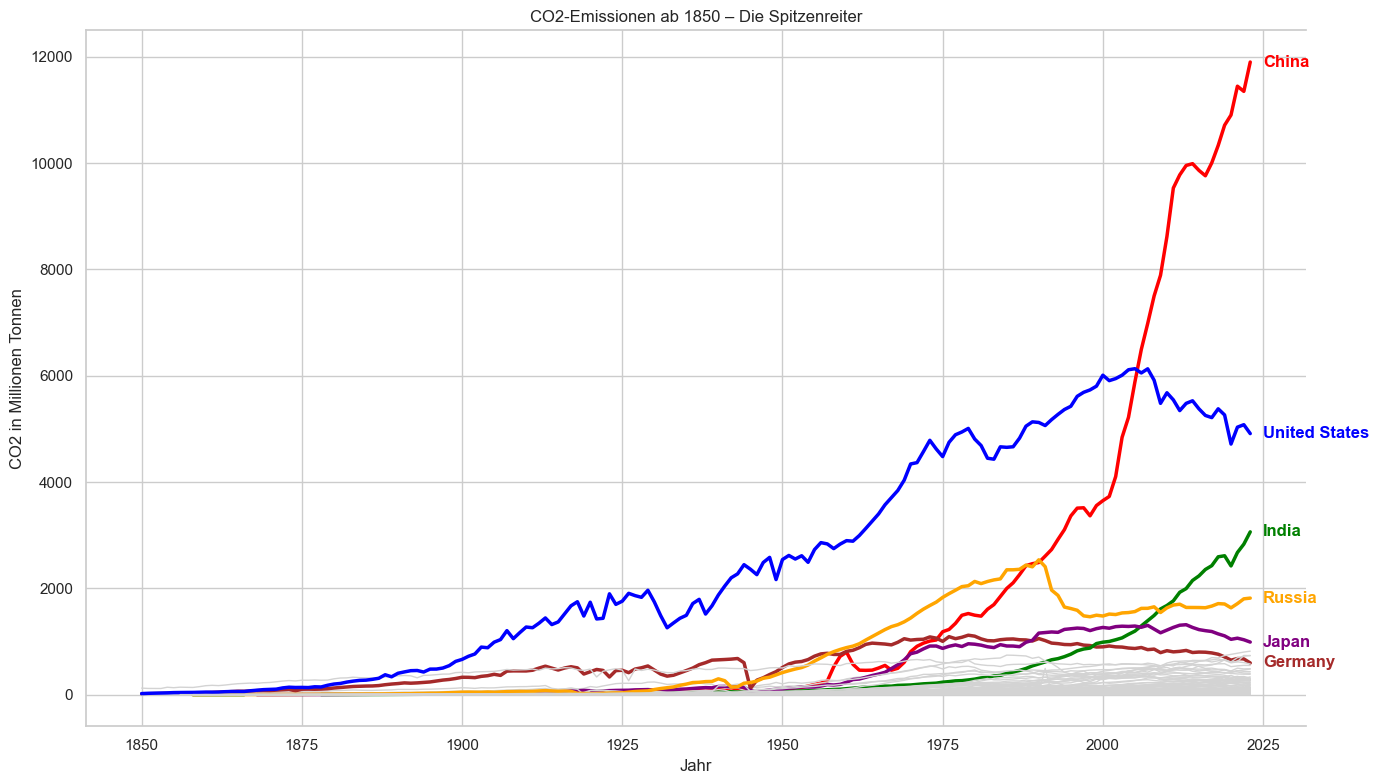

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("owid-co2-data.csv")

laender = ["Afghanistan", "Albania", "Algeria", "Andorra", "Angola", "Antigua and Barbuda", "Argentina", "Armenia", "Australia", "Austria", "Azerbaijan", "Bahamas", "Bahrain", "Bangladesh", "Barbados", "Belarus", "Belgium", "Belize", "Benin", "Bhutan", "Bolivia", "Bosnia and Herzegovina", "Botswana", "Brazil", "Brunei", "Bulgaria", "Burkina Faso", "Burundi", "Cambodia", "Cameroon", "Canada", "Cape Verde", "Central African Republic", "Chad", "Chile", "China", "Colombia", "Comoros", "Congo", "Costa Rica", "Cote d'Ivoire", "Croatia", "Cuba", "Cyprus", "Czechia", "Democratic Republic of Congo", "Denmark", "Djibouti", "Dominica", "Dominican Republic", "East Timor", "Ecuador", "Egypt", "El Salvador", "Equatorial Guinea", "Eritrea", "Estonia", "Eswatini", "Ethiopia", "Fiji", "Finland", "France", "Gabon", "Gambia", "Georgia", "Germany", "Ghana", "Greece", "Grenada", "Guatemala", "Guinea", "Guinea-Bissau", "Guyana", "Haiti", "Honduras", "Hungary", "Iceland", "India", "Indonesia", "Iran", "Iraq", "Ireland", "Israel", "Italy", "Jamaica", "Japan", "Jordan", "Kazakhstan", "Kenya", "Kiribati", "Kosovo", "Kuwait", "Kyrgyzstan", "Laos", "Latvia", "Lebanon", "Lesotho", "Liberia", "Libya", "Liechtenstein", "Lithuania", "Luxembourg", "Madagascar", "Malawi", "Malaysia", "Maldives", "Mali", "Malta", "Marshall Islands", "Mauritania", "Mauritius", "Mexico", "Micronesia (country)", "Moldova", "Monaco", "Mongolia", "Montenegro", "Morocco", "Mozambique", "Myanmar", "Namibia", "Nauru", "Nepal", "Netherlands", "New Zealand", "Nicaragua", "Niger", "Nigeria", "North Korea", "North Macedonia", "Norway", "Oman", "Pakistan", "Palau", "Palestine", "Panama", "Papua New Guinea", "Paraguay", "Peru", "Philippines", "Poland", "Portugal", "Qatar", "Romania", "Russia", "Rwanda", "Saint Kitts and Nevis", "Saint Lucia", "Saint Vincent and the Grenadines", "Samoa", "San Marino", "Sao Tome and Principe", "Saudi Arabia", "Senegal", "Serbia", "Seychelles", "Sierra Leone", "Singapore", "Slovakia", "Slovenia", "Solomon Islands", "Somalia", "South Africa", "South Korea", "South Sudan", "Spain", "Sri Lanka", "Sudan", "Suriname", "Sweden", "Switzerland", "Syria", "Taiwan", "Tajikistan", "Tanzania", "Thailand", "Togo", "Tonga", "Trinidad and Tobago", "Tunisia", "Turkey", "Turkmenistan", "Tuvalu", "Uganda", "Ukraine", "United Arab Emirates", "United Kingdom", "United States", "Uruguay", "Uzbekistan", "Vanuatu", "Vatican", "Venezuela", "Vietnam", "Yemen", "Zambia", "Zimbabwe"]
highlight_laender = ['China', 'United States', 'India', 'Russia', 'Japan', 'Germany']
farben = {
    'China': 'red',
    'United States': 'blue',
    'India': 'green',
    'Russia': 'orange',
    'Japan': 'purple',
    'Germany': 'brown'
}

df_laender = df[df['country'].isin(laender)]
df_laender = df_laender[df_laender['year'] >= 1850]
letztes_jahr = df_laender['year'].max()

plt.figure(figsize=(14, 8))

for land in laender:
    daten_land = df_laender[df_laender['country'] == land]
    if daten_land['co2'].notna().any():
        if land in highlight_laender:
            plt.plot(daten_land['year'], daten_land['co2'], linewidth=2.5, color=farben[land])
            
            last_valid = daten_land.dropna(subset=['co2']).iloc[-1]
            plt.text(last_valid['year'] + 2, last_valid['co2'], land,
                    color=farben[land], fontsize=12, fontweight='bold', va='center')

        else:
            plt.plot(daten_land['year'], daten_land['co2'], color='lightgray', linewidth=1)

plt.title('CO2-Emissionen ab 1850 – Die Spitzenreiter')
plt.xlabel('Jahr')
plt.ylabel('CO2 in Millionen Tonnen')
plt.grid(True)
plt.tight_layout()
plt.gca().spines['right'].set_visible(False)
plt.show()


Lange waren die USA der größte Emittent. Seit etwa 2005 liegt China vorne und stößt heute mehr als doppelt so viel aus.

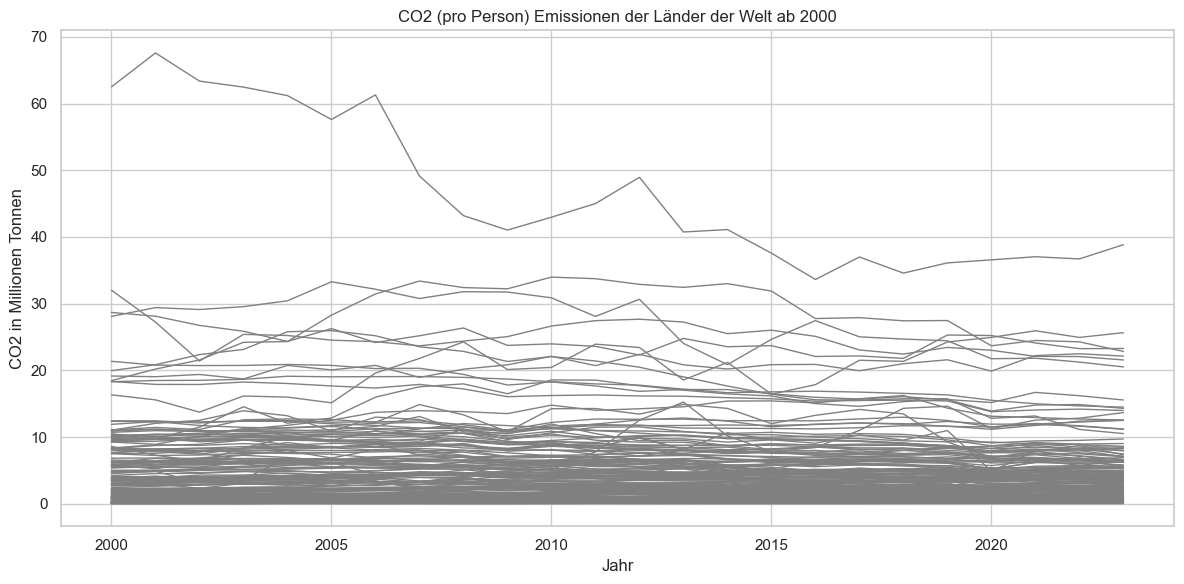

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("owid-co2-data.csv")

laender = ["Afghanistan", "Albania", "Algeria", "Andorra", "Angola", "Antigua and Barbuda", "Argentina", "Armenia", "Australia", "Austria", "Azerbaijan", "Bahamas", "Bahrain", "Bangladesh", "Barbados", "Belarus", "Belgium", "Belize", "Benin", "Bhutan", "Bolivia", "Bosnia and Herzegovina", "Botswana", "Brazil", "Brunei", "Bulgaria", "Burkina Faso", "Burundi", "Cambodia", "Cameroon", "Canada", "Cape Verde", "Central African Republic", "Chad", "Chile", "China", "Colombia", "Comoros", "Congo", "Costa Rica", "Cote d'Ivoire", "Croatia", "Cuba", "Cyprus", "Czechia", "Democratic Republic of Congo", "Denmark", "Djibouti", "Dominica", "Dominican Republic", "East Timor", "Ecuador", "Egypt", "El Salvador", "Equatorial Guinea", "Eritrea", "Estonia", "Eswatini", "Ethiopia", "Fiji", "Finland", "France", "Gabon", "Gambia", "Georgia", "Germany", "Ghana", "Greece", "Grenada", "Guatemala", "Guinea", "Guinea-Bissau", "Guyana", "Haiti", "Honduras", "Hungary", "Iceland", "India", "Indonesia", "Iran", "Iraq", "Ireland", "Israel", "Italy", "Jamaica", "Japan", "Jordan", "Kazakhstan", "Kenya", "Kiribati", "Kosovo", "Kuwait", "Kyrgyzstan", "Laos", "Latvia", "Lebanon", "Lesotho", "Liberia", "Libya", "Liechtenstein", "Lithuania", "Luxembourg", "Madagascar", "Malawi", "Malaysia", "Maldives", "Mali", "Malta", "Marshall Islands", "Mauritania", "Mauritius", "Mexico", "Micronesia (country)", "Moldova", "Monaco", "Mongolia", "Montenegro", "Morocco", "Mozambique", "Myanmar", "Namibia", "Nauru", "Nepal", "Netherlands", "New Zealand", "Nicaragua", "Niger", "Nigeria", "North Korea", "North Macedonia", "Norway", "Oman", "Pakistan", "Palau", "Palestine", "Panama", "Papua New Guinea", "Paraguay", "Peru", "Philippines", "Poland", "Portugal", "Qatar", "Romania", "Russia", "Rwanda", "Saint Kitts and Nevis", "Saint Lucia", "Saint Vincent and the Grenadines", "Samoa", "San Marino", "Sao Tome and Principe", "Saudi Arabia", "Senegal", "Serbia", "Seychelles", "Sierra Leone", "Singapore", "Slovakia", "Slovenia", "Solomon Islands", "Somalia", "South Africa", "South Korea", "South Sudan", "Spain", "Sri Lanka", "Sudan", "Suriname", "Sweden", "Switzerland", "Syria", "Taiwan", "Tajikistan", "Tanzania", "Thailand", "Togo", "Tonga", "Trinidad and Tobago", "Tunisia", "Turkey", "Turkmenistan", "Tuvalu", "Uganda", "Ukraine", "United Arab Emirates", "United Kingdom", "United States", "Uruguay", "Uzbekistan", "Vanuatu", "Vatican", "Venezuela", "Vietnam", "Yemen", "Zambia", "Zimbabwe"]
df_laender = df[df['country'].isin(laender)]

startjahr = 2000
df_laender = df_laender[df_laender['year'] >= startjahr]

plt.figure(figsize=(12, 6))
for land in laender:
    daten_land = df_laender[df_laender['country'] == land]
    plt.plot(daten_land['year'], daten_land['co2_per_capita'], color='gray', linewidth=1)

plt.title('CO2 (pro Person) Emissionen der Länder der Welt ab 2000')
plt.xlabel('Jahr')
plt.ylabel('CO2 in Millionen Tonnen')
plt.grid(True)
plt.tight_layout()
plt.show()

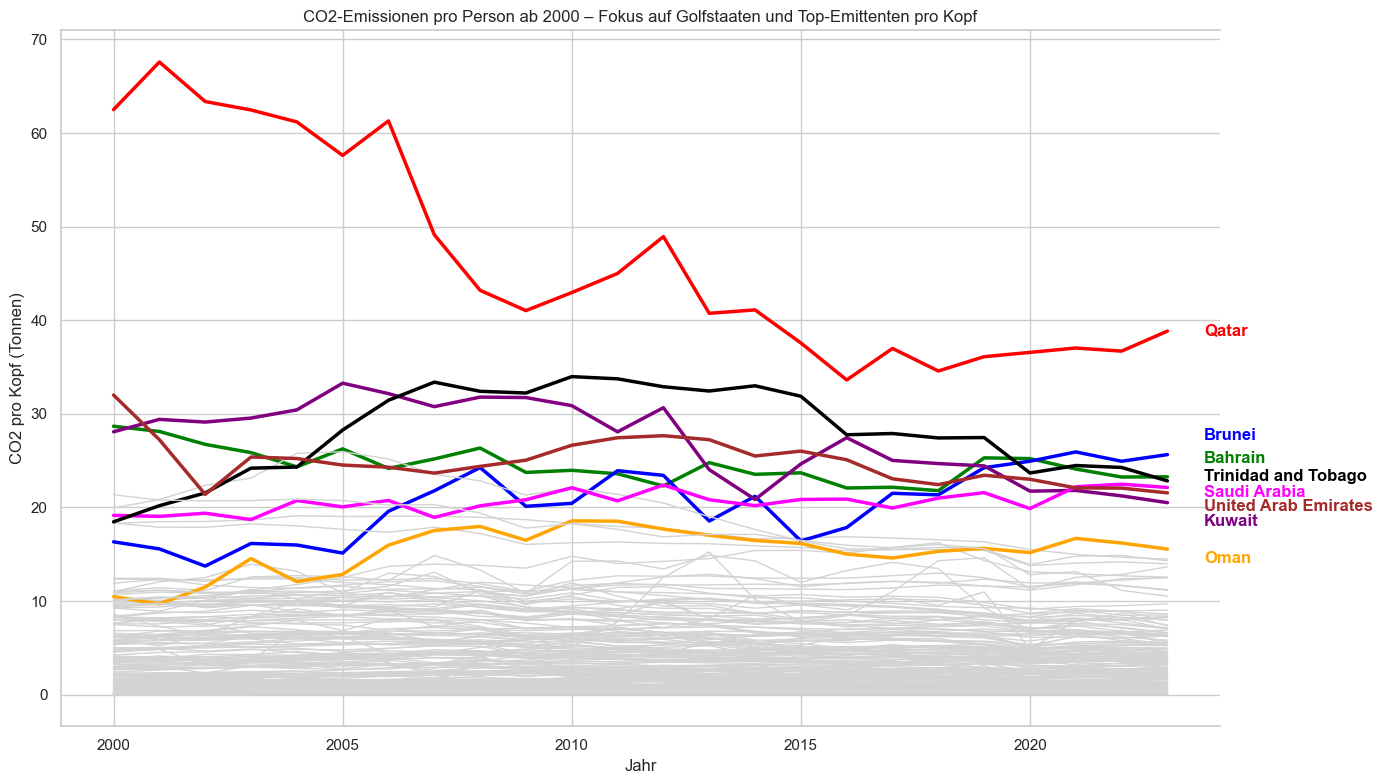

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("owid-co2-data.csv")

laender = ["Afghanistan", "Albania", "Algeria", "Andorra", "Angola", "Antigua and Barbuda", "Argentina", "Armenia", "Australia", "Austria", "Azerbaijan", "Bahamas", "Bahrain", "Bangladesh", "Barbados", "Belarus", "Belgium", "Belize", "Benin", "Bhutan", "Bolivia", "Bosnia and Herzegovina", "Botswana", "Brazil", "Brunei", "Bulgaria", "Burkina Faso", "Burundi", "Cambodia", "Cameroon", "Canada", "Cape Verde", "Central African Republic", "Chad", "Chile", "China", "Colombia", "Comoros", "Congo", "Costa Rica", "Cote d'Ivoire", "Croatia", "Cuba", "Cyprus", "Czechia", "Democratic Republic of Congo", "Denmark", "Djibouti", "Dominica", "Dominican Republic", "East Timor", "Ecuador", "Egypt", "El Salvador", "Equatorial Guinea", "Eritrea", "Estonia", "Eswatini", "Ethiopia", "Fiji", "Finland", "France", "Gabon", "Gambia", "Georgia", "Germany", "Ghana", "Greece", "Grenada", "Guatemala", "Guinea", "Guinea-Bissau", "Guyana", "Haiti", "Honduras", "Hungary", "Iceland", "India", "Indonesia", "Iran", "Iraq", "Ireland", "Israel", "Italy", "Jamaica", "Japan", "Jordan", "Kazakhstan", "Kenya", "Kiribati", "Kosovo", "Kuwait", "Kyrgyzstan", "Laos", "Latvia", "Lebanon", "Lesotho", "Liberia", "Libya", "Liechtenstein", "Lithuania", "Luxembourg", "Madagascar", "Malawi", "Malaysia", "Maldives", "Mali", "Malta", "Marshall Islands", "Mauritania", "Mauritius", "Mexico", "Micronesia (country)", "Moldova", "Monaco", "Mongolia", "Montenegro", "Morocco", "Mozambique", "Myanmar", "Namibia", "Nauru", "Nepal", "Netherlands", "New Zealand", "Nicaragua", "Niger", "Nigeria", "North Korea", "North Macedonia", "Norway", "Oman", "Pakistan", "Palau", "Palestine", "Panama", "Papua New Guinea", "Paraguay", "Peru", "Philippines", "Poland", "Portugal", "Qatar", "Romania", "Russia", "Rwanda", "Saint Kitts and Nevis", "Saint Lucia", "Saint Vincent and the Grenadines", "Samoa", "San Marino", "Sao Tome and Principe", "Saudi Arabia", "Senegal", "Serbia", "Seychelles", "Sierra Leone", "Singapore", "Slovakia", "Slovenia", "Solomon Islands", "Somalia", "South Africa", "South Korea", "South Sudan", "Spain", "Sri Lanka", "Sudan", "Suriname", "Sweden", "Switzerland", "Syria", "Taiwan", "Tajikistan", "Tanzania", "Thailand", "Togo", "Tonga", "Trinidad and Tobago", "Tunisia", "Turkey", "Turkmenistan", "Tuvalu", "Uganda", "Ukraine", "United Arab Emirates", "United Kingdom", "United States", "Uruguay", "Uzbekistan", "Vanuatu", "Vatican", "Venezuela", "Vietnam", "Yemen", "Zambia", "Zimbabwe"]

highlight_laender = ['Qatar', 'Brunei', 'Bahrain', 'Oman', 'Kuwait', 'United Arab Emirates', 'Saudi Arabia', 'Trinidad and Tobago']
farben = {
    'Qatar': 'red',
    'Brunei': 'blue',
    'Bahrain': 'green',
    'Oman': 'orange',
    'Kuwait': 'purple',
    'United Arab Emirates': 'brown',
    'Saudi Arabia': 'magenta',
    'Trinidad and Tobago': 'black'
}

offsets = {
    'Qatar': 0,
    'Brunei': 2.0,
    'Bahrain': 2.0,
    'Oman': -1.0,
    'Kuwait': -2.0,
    'United Arab Emirates': -1.5,
    'Saudi Arabia': -0.5,
    'Trinidad and Tobago': 0.5
}

df_laender = df[df['country'].isin(laender)]
df_laender = df_laender[df_laender['year'] >= 2000]
letztes_jahr = df_laender['year'].max()

plt.figure(figsize=(14, 8))

for land in laender:
    daten_land = df_laender[df_laender['country'] == land]
    if daten_land['co2_per_capita'].notna().any():
        if land in highlight_laender:
            plt.plot(daten_land['year'], daten_land['co2_per_capita'], linewidth=2.5, color=farben[land])
            
            last_valid = daten_land.dropna(subset=['co2_per_capita']).iloc[-1]
            offset = offsets.get(land, 0)
            plt.text(
                last_valid['year'] + 0.8,
                last_valid['co2_per_capita'] + offset,
                land,
                color=farben[land],
                fontsize=12,
                fontweight='bold',
                va='center'
            )
        else:
            plt.plot(daten_land['year'], daten_land['co2_per_capita'], color='lightgray', linewidth=1)

plt.title('CO2-Emissionen pro Person ab 2000 – Fokus auf Golfstaaten und Top-Emittenten pro Kopf')
plt.xlabel('Jahr')
plt.ylabel('CO2 pro Kopf (Tonnen)')
plt.grid(True)
plt.gca().spines['right'].set_visible(False)
plt.tight_layout()
plt.show()


Pro Kopf sieht die Rangliste ganz anders aus: Hier führen kleine Golfstaaten wie Katar mit sehr hohem Energieverbrauch pro Person.

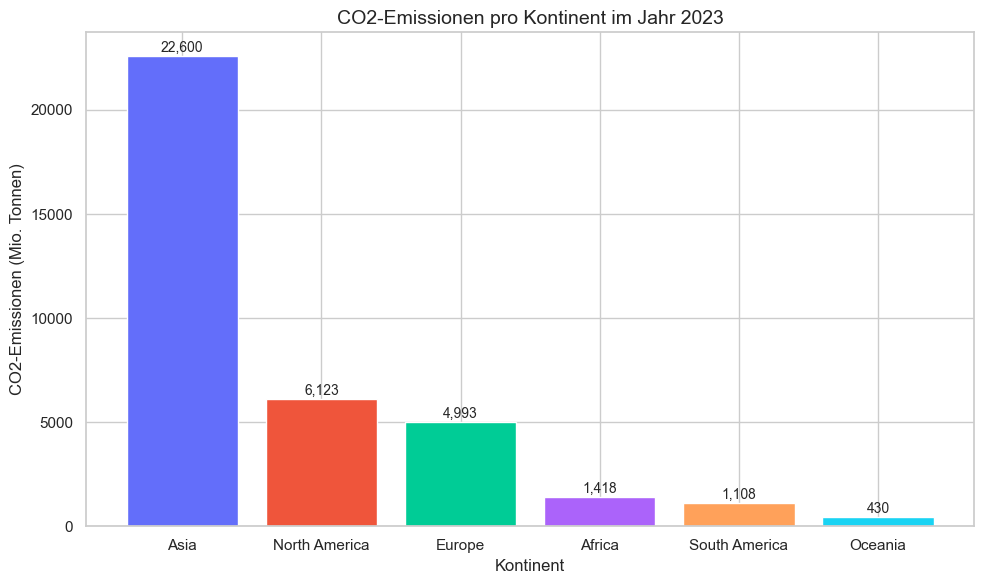

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("owid-co2-data.csv")

jahr = 2023

kontinente = ["Africa", "Asia", "Europe", "North America", "South America", "Oceania"]

df_kont = df[
    (df['year'] == jahr) &
    (df['country'].isin(kontinente)) &
    (df['co2'].notna())
]

df_kont = df_kont.sort_values(by='co2', ascending=False)

farben = ['#636EFA', '#EF553B', '#00CC96', '#AB63FA', '#FFA15A', '#19D3F3']
plt.figure(figsize=(10, 6))
bars = plt.bar(df_kont['country'], df_kont['co2'], color=farben)

plt.title("CO2-Emissionen pro Kontinent im Jahr 2023", fontsize=14)
plt.xlabel("Kontinent")
plt.ylabel("CO2-Emissionen (Mio. Tonnen)")

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 50, f"{int(yval):,}", ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


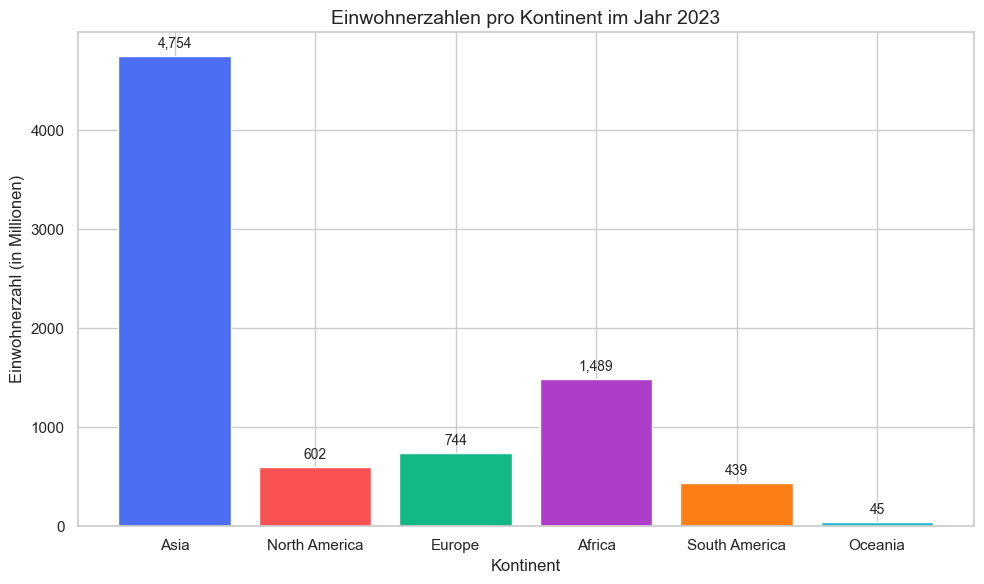

In [16]:
import matplotlib.pyplot as plt

kontinente = ["Asia", "North America", "Europe", "Africa", "South America", "Oceania"]
einwohner_mio = [4754, 602, 744, 1489, 439, 45]

farben = {
    "Asia": "#4c6ef5",
    "North America": "#fa5252",
    "Europe": "#12b886",
    "Africa": "#ae3ec9",
    "South America": "#fd7e14",
    "Oceania": "#22b8cf"
}

farben_liste = [farben[k] for k in kontinente]

plt.figure(figsize=(10, 6))
bars = plt.bar(kontinente, einwohner_mio, color=farben_liste)

plt.title("Einwohnerzahlen pro Kontinent im Jahr 2023", fontsize=14)
plt.xlabel("Kontinent")
plt.ylabel("Einwohnerzahl (in Millionen)")

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 50, f"{yval:,}", ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

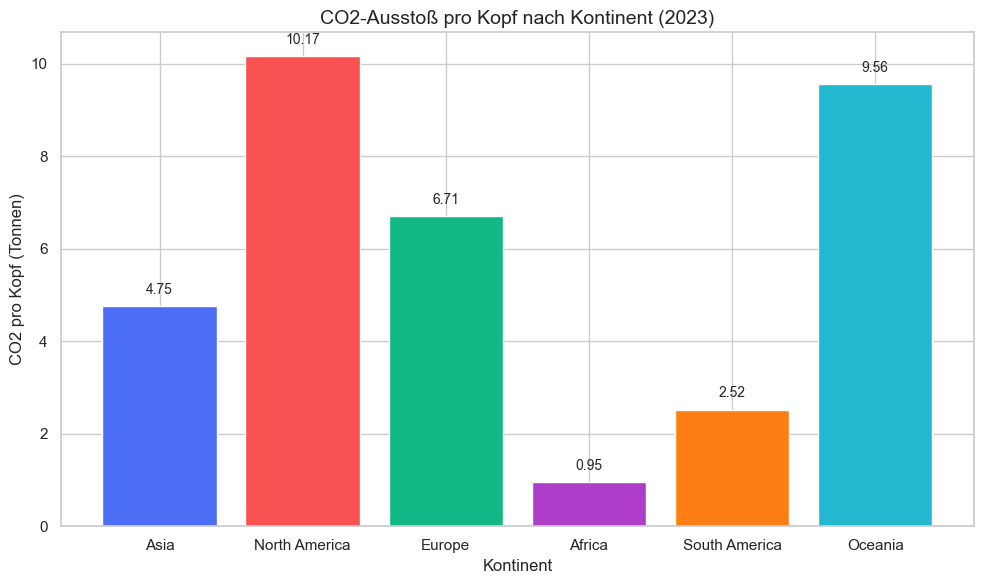

In [17]:
import matplotlib.pyplot as plt

kontinente = ["Asia", "North America", "Europe", "Africa", "South America", "Oceania"]
co2_mio_tonnen = [22600, 6123, 4993, 1418, 1108, 430]
einwohner_mio = [4754, 602, 744, 1489, 439, 45]

co2_pro_kopf = [co2 / bev for co2, bev in zip(co2_mio_tonnen, einwohner_mio)]

farben = {
    "Asia": "#4c6ef5",
    "North America": "#fa5252",
    "Europe": "#12b886",
    "Africa": "#ae3ec9",
    "South America": "#fd7e14",
    "Oceania": "#22b8cf"
}
farben_liste = [farben[k] for k in kontinente]

plt.figure(figsize=(10, 6))
bars = plt.bar(kontinente, co2_pro_kopf, color=farben_liste)

plt.title("CO2-Ausstoß pro Kopf nach Kontinent (2023)", fontsize=14)
plt.xlabel("Kontinent")
plt.ylabel("CO2 pro Kopf (Tonnen)")

for bar, val in zip(bars, co2_pro_kopf):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.2, f"{val:.2f}", ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


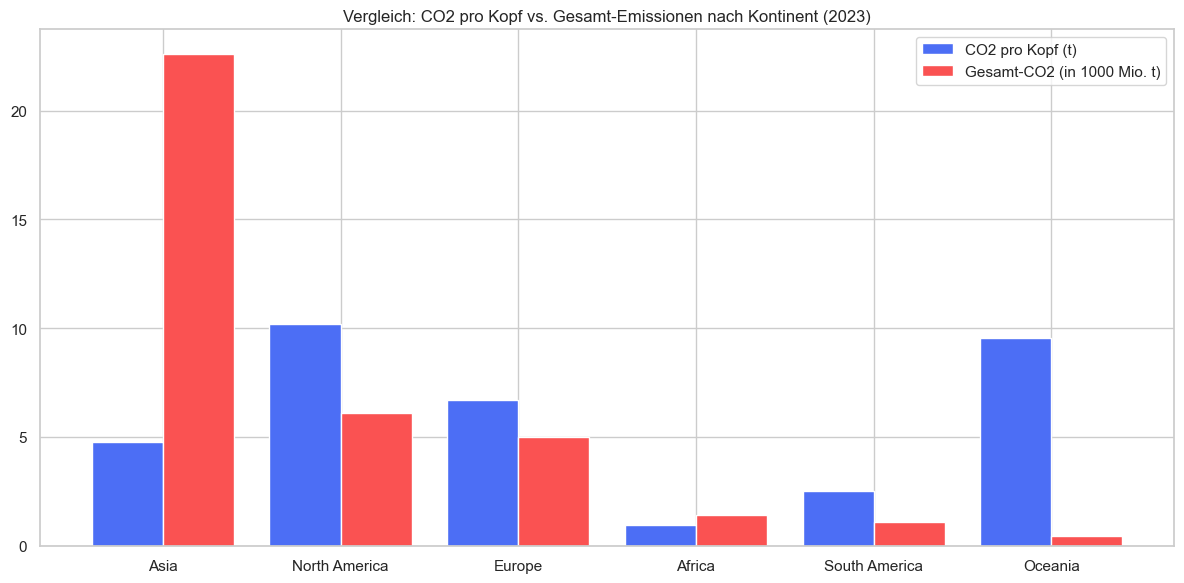

In [18]:
import matplotlib.pyplot as plt
import numpy as np

kontinente = ["Asia", "North America", "Europe", "Africa", "South America", "Oceania"]

co2_mio = [22600, 6123, 4993, 1418, 1108, 430]
bev_mio = [4754, 602, 744, 1489, 439, 45]
co2_pro_kopf = [co2 / bev for co2, bev in zip(co2_mio, bev_mio)]

co2_mio_skaliert = [v / 1000 for v in co2_mio]

x = np.arange(len(kontinente))
width = 0.4

plt.figure(figsize=(12, 6))
plt.bar(x - width/2, co2_pro_kopf, width, label="CO2 pro Kopf (t)", color="#4c6ef5")
plt.bar(x + width/2, co2_mio_skaliert, width, label="Gesamt-CO2 (in 1000 Mio. t)", color="#fa5252")

plt.xticks(x, kontinente)
plt.title("Vergleich: CO2 pro Kopf vs. Gesamt-Emissionen nach Kontinent (2023)")
plt.legend()
plt.tight_layout()
plt.show()

Asien stößt mit Abstand am meisten aus, hat aber auch die meisten Einwohner. Pro Kopf liegen Nordamerika (10,2 t)
und Ozeanien (9,6 t) vorne, Afrika liegt bei unter einer Tonne pro Person.

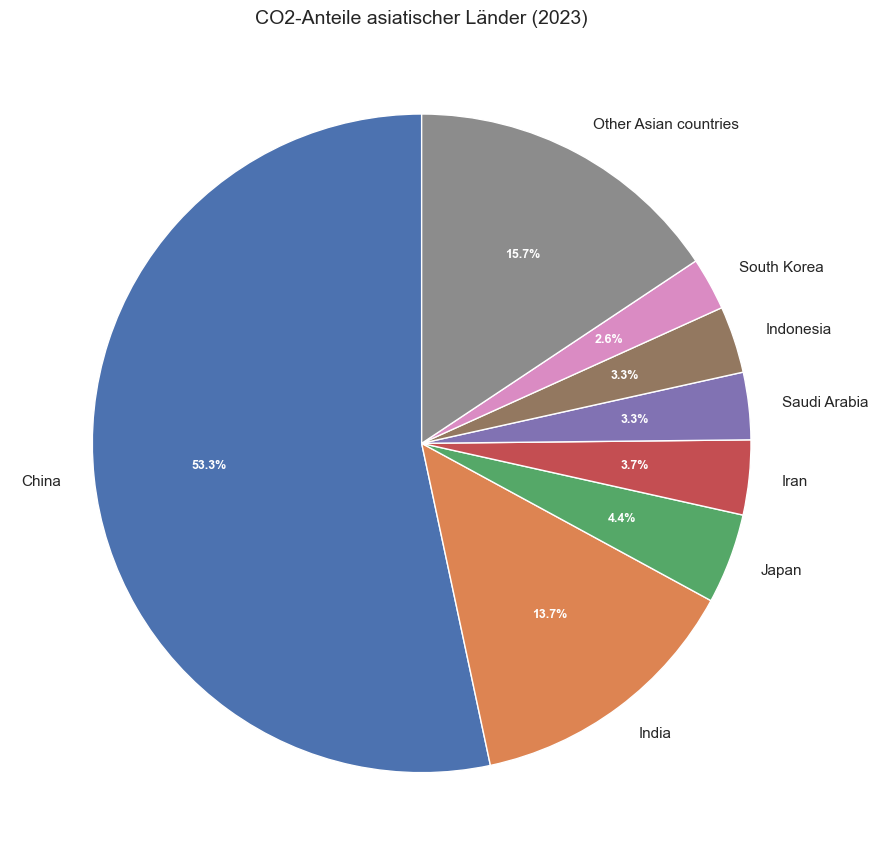

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("owid-co2-data.csv")

jahr = 2023

asiatische_laender = [
    "Afghanistan", "Armenia", "Azerbaijan", "Bahrain", "Bangladesh", "Bhutan", "Brunei",
    "Cambodia", "China", "Cyprus", "East Timor", "Georgia", "India", "Indonesia", "Iran", "Iraq",
    "Israel", "Japan", "Jordan", "Kazakhstan", "Kuwait", "Kyrgyzstan", "Laos", "Lebanon", "Malaysia",
    "Maldives", "Mongolia", "Myanmar", "Nepal", "North Korea", "Oman", "Pakistan", "Palestine",
    "Philippines", "Qatar", "Saudi Arabia", "Singapore", "South Korea", "Sri Lanka", "Syria",
    "Tajikistan", "Thailand", "Turkey", "Turkmenistan", "United Arab Emirates", "Uzbekistan",
    "Vietnam", "Yemen"
]

df_asien = df[
    (df['year'] == jahr) &
    (df['country'].isin(asiatische_laender)) &
    (df['co2'].notna())
].copy()

gesamt = df_asien['co2'].sum()

df_asien['anteil'] = df_asien['co2'] / gesamt * 100

df_top = df_asien[df_asien['anteil'] >= 2].sort_values(by='co2', ascending=False)
df_rest = df_asien[df_asien['anteil'] < 2]

other_sum = df_rest['co2'].sum()
other_anteil = other_sum / gesamt * 100

df_other = pd.DataFrame({
    'country': ['Other Asian countries'],
    'co2': [other_sum],
    'anteil': [other_anteil]
})

df_pie = pd.concat([df_top, df_other], ignore_index=True)

labels = df_pie['country']
werte = df_pie['co2']
prozent = [f"{(v / gesamt * 100):.1f}%" for v in werte]

fig, ax = plt.subplots(figsize=(9, 9))
wedges, texts = ax.pie(werte, labels=labels, startangle=90)

for i, wedge in enumerate(wedges):
    ang = (wedge.theta2 + wedge.theta1) / 2
    x = 0.65 * np.cos(np.radians(ang))
    y = 0.65 * np.sin(np.radians(ang))
    ax.text(x, y, prozent[i], ha='center', va='center', fontsize=9, color='white', weight='bold')

plt.title("CO2-Anteile asiatischer Länder (2023)", fontsize=14)
plt.tight_layout()
plt.show()


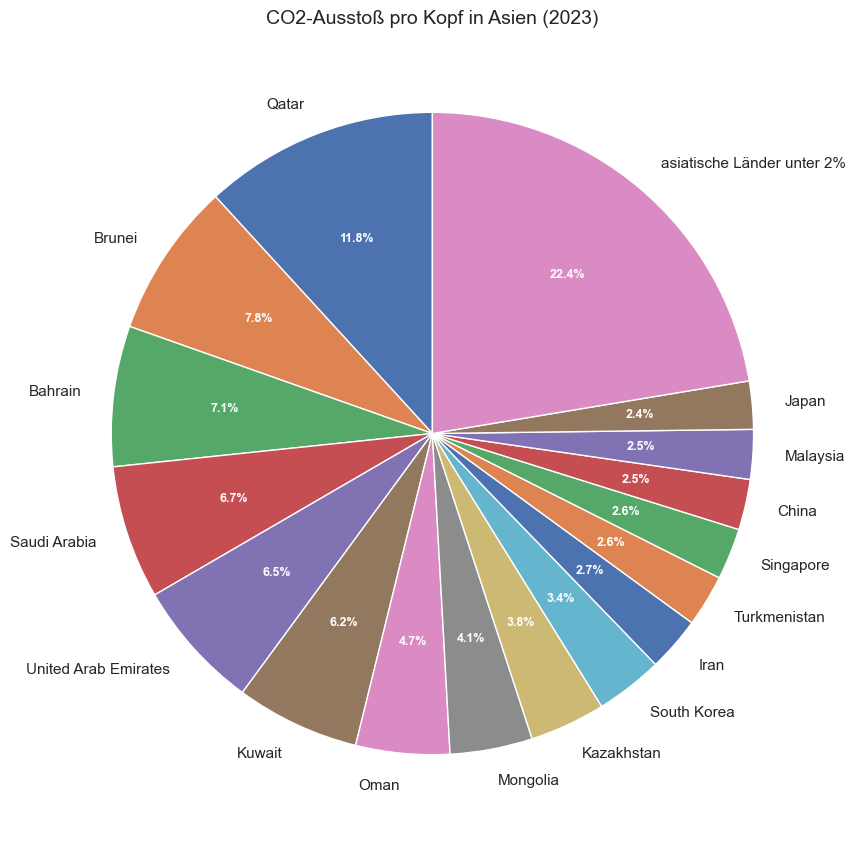

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("owid-co2-data.csv")

jahr = 2023

asiatische_laender = [
    "Afghanistan", "Armenia", "Azerbaijan", "Bahrain", "Bangladesh", "Bhutan", "Brunei",
    "Cambodia", "China", "Cyprus", "East Timor", "Georgia", "India", "Indonesia", "Iran", "Iraq",
    "Israel", "Japan", "Jordan", "Kazakhstan", "Kuwait", "Kyrgyzstan", "Laos", "Lebanon", "Malaysia",
    "Maldives", "Mongolia", "Myanmar", "Nepal", "North Korea", "Oman", "Pakistan", "Palestine",
    "Philippines", "Qatar", "Saudi Arabia", "Singapore", "South Korea", "Sri Lanka", "Syria",
    "Tajikistan", "Thailand", "Turkey", "Turkmenistan", "United Arab Emirates", "Uzbekistan",
    "Vietnam", "Yemen"
]

df_asien = df[
    (df['year'] == jahr) &
    (df['country'].isin(asiatische_laender)) &
    (df['co2_per_capita'].notna())
].copy()

gesamt = df_asien['co2_per_capita'].sum()

df_asien['anteil'] = df_asien['co2_per_capita'] / gesamt * 100

df_top = df_asien[df_asien['anteil'] >= 2].sort_values(by='co2_per_capita', ascending=False)
df_rest = df_asien[df_asien['anteil'] < 2]

other_sum = df_rest['co2_per_capita'].sum()
other_anteil = other_sum / gesamt * 100

df_other = pd.DataFrame({
    'country': ['asiatische Länder unter 2%'],
    'co2_per_capita': [other_sum],
    'anteil': [other_anteil]
})

df_pie = pd.concat([df_top[['country', 'co2_per_capita', 'anteil']], df_other], ignore_index=True)

labels = df_pie['country']
werte = df_pie['co2_per_capita']
prozent = [f"{(v / gesamt * 100):.1f}%" for v in werte]

fig, ax = plt.subplots(figsize=(9, 9))
wedges, texts = ax.pie(werte, labels=labels, startangle=90)

for i, wedge in enumerate(wedges):
    ang = (wedge.theta2 + wedge.theta1) / 2
    x = 0.65 * np.cos(np.radians(ang))
    y = 0.65 * np.sin(np.radians(ang))
    ax.text(x, y, prozent[i], ha='center', va='center', fontsize=9, color='white', weight='bold')

plt.title("CO2-Ausstoß pro Kopf in Asien (2023)", fontsize=14)
plt.tight_layout()
plt.show()


Innerhalb Asiens verursacht China rund die Hälfte der Emissionen. Pro Kopf liegen dagegen wieder die Golfstaaten vorne.

**Interaktive Grafiken:** Die nächsten drei Zellen erzeugen Plotly-Grafiken und speichern sie als HTML in `docs/`.
Ihre Ausgaben haben wir hier entfernt, weil GitHub sie im Notebook nicht anzeigt. Live ansehen kann man sie hier:
[Sunburst nach Kontinent und Land](https://adamst-git.github.io/climate-change-in-data/SunBurst.html),
[animierte Weltkarte der CO2-Emissionen](https://adamst-git.github.io/climate-change-in-data/Karte-CO2-Animation.html) und
[Weltkarte pro Kopf](https://adamst-git.github.io/climate-change-in-data/Karte-Pro-Person.html).

In [21]:
import pandas as pd
import plotly.express as px
import plotly.io as pio

df = pd.read_csv("owid-co2-data.csv")

df_länder = df[
    (df['year'] == 2023) &
    (df['iso_code'].notna()) &
    (df['co2'].notna())
].copy()

kontinent_map = {
    "China": "Asia", "India": "Asia", "Japan": "Asia", "Indonesia": "Asia", "Iran": "Asia",
    "Saudi Arabia": "Asia", "South Korea": "Asia", "Vietnam": "Asia", "Thailand": "Asia", "Singapore": "Asia",
    "Russia": "Europe", "Germany": "Europe", "France": "Europe", "United Kingdom": "Europe",
    "Italy": "Europe", "Spain": "Europe", "Poland": "Europe", "Ireland": "Europe", "Switzerland": "Europe",
    "United States": "North America", "Canada": "North America", "Mexico": "North America",
    "Brazil": "South America", "Argentina": "South America", "Colombia": "South America",
    "South Africa": "Africa", "Egypt": "Africa", "Nigeria": "Africa",
    "Australia": "Oceania", "New Zealand": "Oceania"
}

df_länder["continent"] = df_länder["country"].map(kontinent_map)
df_länder = df_länder[df_länder["continent"].notna()]

custom_colors = {
    "Asia": "#e74c3c",           # rot
    "Europe": "#f1c40f",         # gelb
    "North America": "#3498db", # blau
    "South America": "#5dade2", # hellblau
    "Africa": "#58d68d",        # grün
    "Oceania": "#8e44ad"        # violett
}

fig = px.sunburst(
    df_länder,
    path=["continent", "country"],
    values="co2",
    color="continent",
    color_discrete_map=custom_colors,
    title="🌍 CO₂-Ausstoß nach Kontinent und Land (2023)"
)

fig.update_layout(margin=dict(t=50, l=0, r=0, b=0))
fig.show()

pio.write_html(fig, file="docs/SunBurst.html", auto_open=True)

In [22]:
import pandas as pd
import plotly.express as px

pio.renderers.default = "notebook_connected"

df = pd.read_csv("owid-co2-data.csv")

df_anim = df[
    (df['year'] >= 1950) &
    df['iso_code'].notna() &
    df['co2'].notna()
]

fine_gradient = [
    [0.00, "#edf8fb"],
    [0.03, "#b2e2e2"],  
    [0.05, "#66c2a4"],
    [0.10, "#2ca25f"], 
    [0.15, "#006d2c"],
    [0.50, "#fee08b"],
    [0.75, "#f46d43"],
    [0.90, "#d73027"],
    [1.00, "#7f0000"]
]

fig = px.choropleth(
    df_anim,
    locations="iso_code",
    color="co2",
    hover_name="country",
    animation_frame="year",
    color_continuous_scale=fine_gradient ,
    range_color=(0, 7000),
    title="CO₂-Emissionen weltweit (1900–heute, Skala bis 5000)",
    labels={'co2': 'CO2 (Mio. Tonnen)'}
)

fig.update_layout(
    margin={"r":0,"t":40,"l":0,"b":0}
)

fig.show()

pio.write_html(fig, file="docs/Karte-CO2-Animation.html", auto_open=True)

In [23]:
import pandas as pd
import plotly.express as px

df = pd.read_csv("owid-co2-data.csv")

df_2023 = df[(df["year"] == 2023) & (df["iso_code"].str.len() == 3)]
df_2023 = df_2023[["iso_code", "country", "co2_per_capita"]].dropna()

fine_gradient = [
    [0.00, "#edf8fb"],
    [0.03, "#b2e2e2"],
    [0.05, "#66c2a4"],
    [0.10, "#2ca25f"],
    [0.15, "#006d2c"],
    [0.50, "#fee08b"],
    [0.75, "#f46d43"],
    [0.90, "#d73027"],
    [1.00, "#7f0000"]
]

fig = px.choropleth(
    df_2023,
    locations="iso_code",
    color="co2_per_capita",
    hover_name="country",
    color_continuous_scale=fine_gradient,
    range_color=[0, 25],
    title="CO₂-Emissionen pro Kopf weltweit im Jahr 2023 (Tonnen pro Person)",
    labels={'co2_per_capita': 't CO₂ / Person'}
)

fig.update_geos(showcountries=True, showcoastlines=True, projection_type="natural earth")
fig.update_layout(margin={"r":0,"t":50,"l":0,"b":0})
fig.show()

pio.write_html(fig, file="docs/Karte-Pro-Person.html", auto_open=True)

---
# 4. Veränderung der Welt

Wie wirkt sich die Erwärmung aus? Wir betrachten Meeresspiegel, Meereis, Extremwetter und Krankheiten.

> **Hinweis:** Die Rohdaten dieses Kapitels liegen nicht im Repository. Die Diagramme stammen aus unserem
> ursprünglichen Lauf, deshalb haben diese Zellen keine Ausführungsnummer. Die Quellen stehen in der README.

## Meeresspiegel

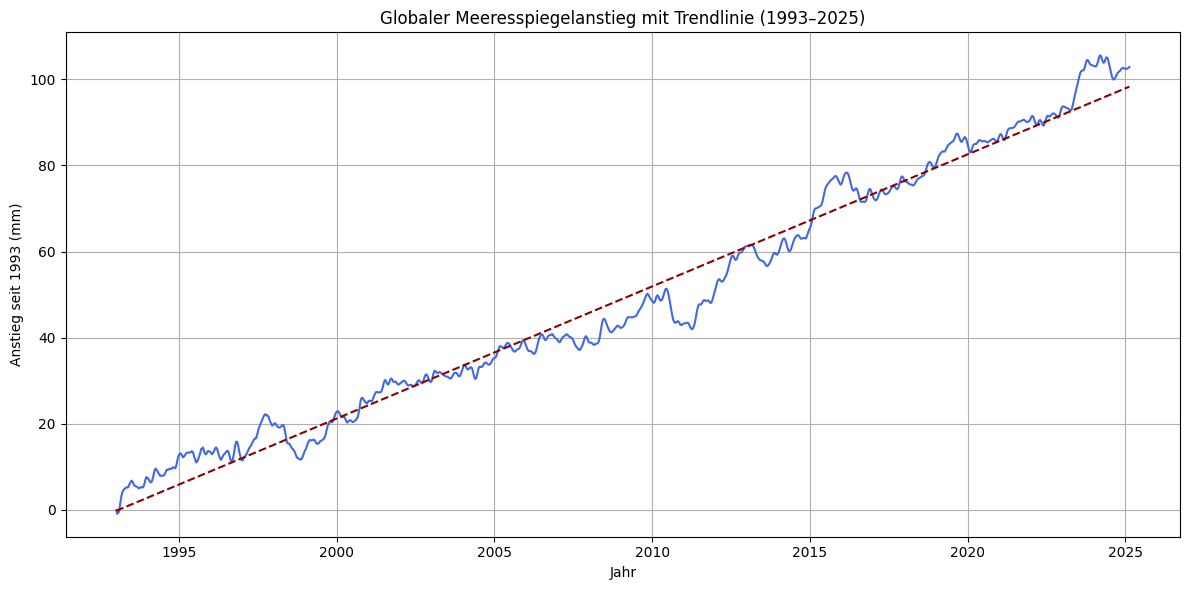

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


df = pd.read_csv("sea_level_data.csv", comment="H", delim_whitespace=True, header=None)
df_sea = df[[2, 12]].copy()
df_sea.columns = ["Year", "GMSL_mm"]


start_level = df_sea["GMSL_mm"].iloc[0]
df_sea["Relative_Anstieg_mm"] = df_sea["GMSL_mm"] - start_level


z = np.polyfit(df_sea["Year"], df_sea["Relative_Anstieg_mm"], 1)
p = np.poly1d(z)


plt.figure(figsize=(12, 6))
plt.plot(df_sea["Year"], df_sea["Relative_Anstieg_mm"], color="royalblue", label="Relativer Anstieg seit 1993")
plt.plot(df_sea["Year"], p(df_sea["Year"]), "--", color="darkred", label=f"Trend: {z[0]:.2f} mm/Jahr")
plt.title("Globaler Meeresspiegelanstieg mit Trendlinie (1993–2025)")
plt.xlabel("Jahr")
plt.ylabel("Anstieg seit 1993 (mm)")
plt.grid(True)
plt.tight_layout()
plt.show()


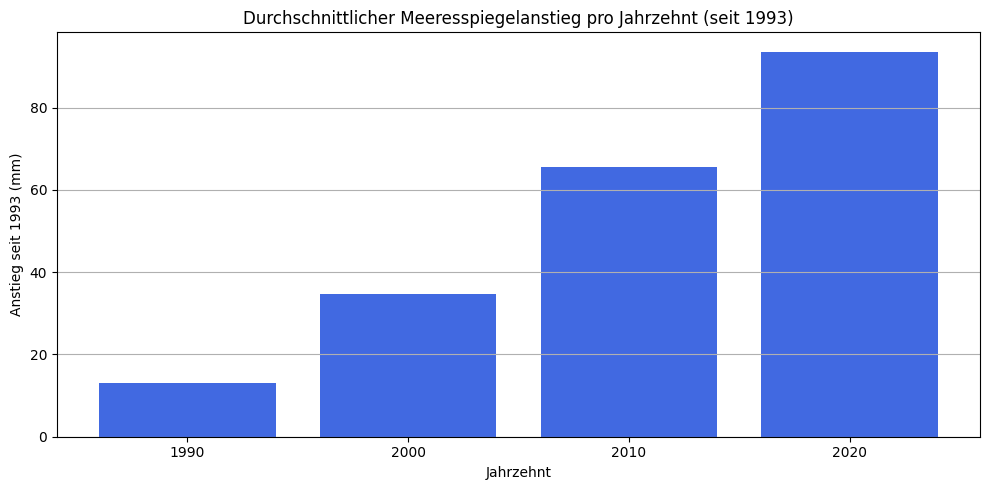

In [ ]:

df_sea["Decade"] = (df_sea["Year"] // 10) * 10
decadal_avg = df_sea.groupby("Decade")["Relative_Anstieg_mm"].mean().reset_index()


plt.figure(figsize=(10, 5))
plt.bar(decadal_avg["Decade"].astype(int).astype(str), decadal_avg["Relative_Anstieg_mm"], color="royalblue")
plt.title("Durchschnittlicher Meeresspiegelanstieg pro Jahrzehnt (seit 1993)")
plt.xlabel("Jahrzehnt")
plt.ylabel("Anstieg seit 1993 (mm)")
plt.grid(axis="y")
plt.tight_layout()
plt.show()


Seit 1993 ist der Meeresspiegel um rund 10 cm gestiegen, und der Anstieg pro Jahrzehnt wird größer.

## Meereis

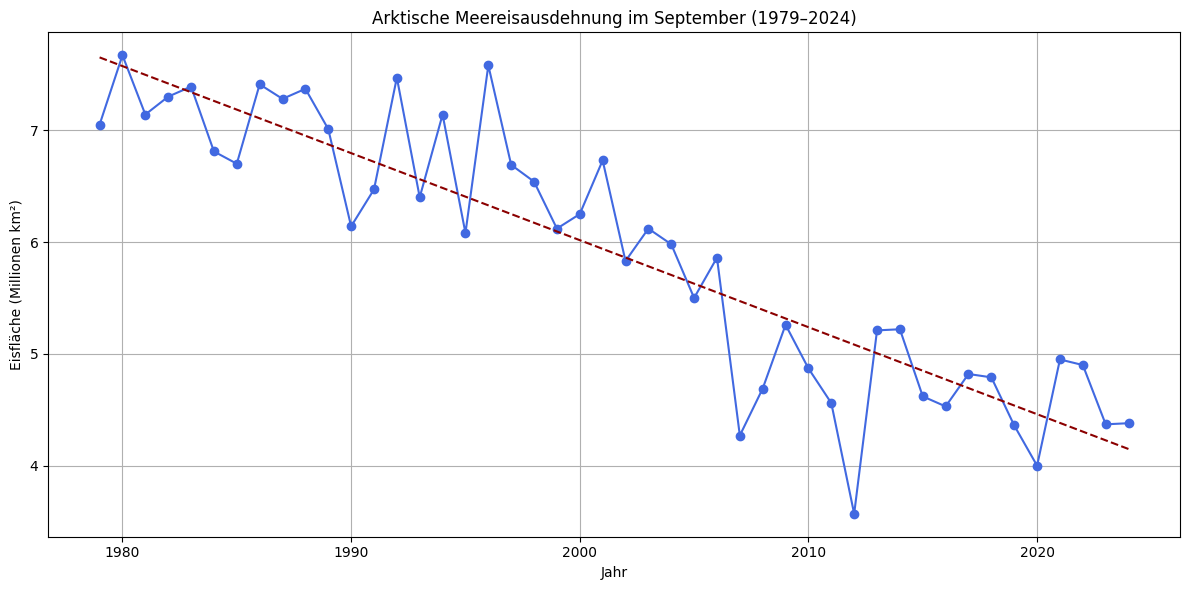

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


file_path = "N_09_extent_v3.0.csv"
df = pd.read_csv(file_path, header=None)


df.columns = ["Year", "Month", "Source", "Region", "Extent", "Area"]


df = df[["Year", "Extent"]].copy()
df["Year"] = pd.to_numeric(df["Year"], errors='coerce')
df["Extent"] = pd.to_numeric(df["Extent"], errors='coerce')


import numpy as np

df = df.dropna(subset=["Year", "Extent"])

z = np.polyfit(df["Year"], df["Extent"], 1)
p = np.poly1d(z)


plt.figure(figsize=(12, 6))
plt.plot(df["Year"], df["Extent"], marker='o', linestyle='-', color='royalblue', label="Meereisausdehnung im September")
plt.plot(df["Year"], p(df["Year"]), linestyle='--', color='darkred', label=f"Trendlinie ({z[0]:.2f} Mio. km²/Jahr)")
plt.title("Arktische Meereisausdehnung im September (1979–2024)")
plt.xlabel("Jahr")
plt.ylabel("Eisfläche (Millionen km²)")
plt.grid(True)
plt.tight_layout()
plt.show()


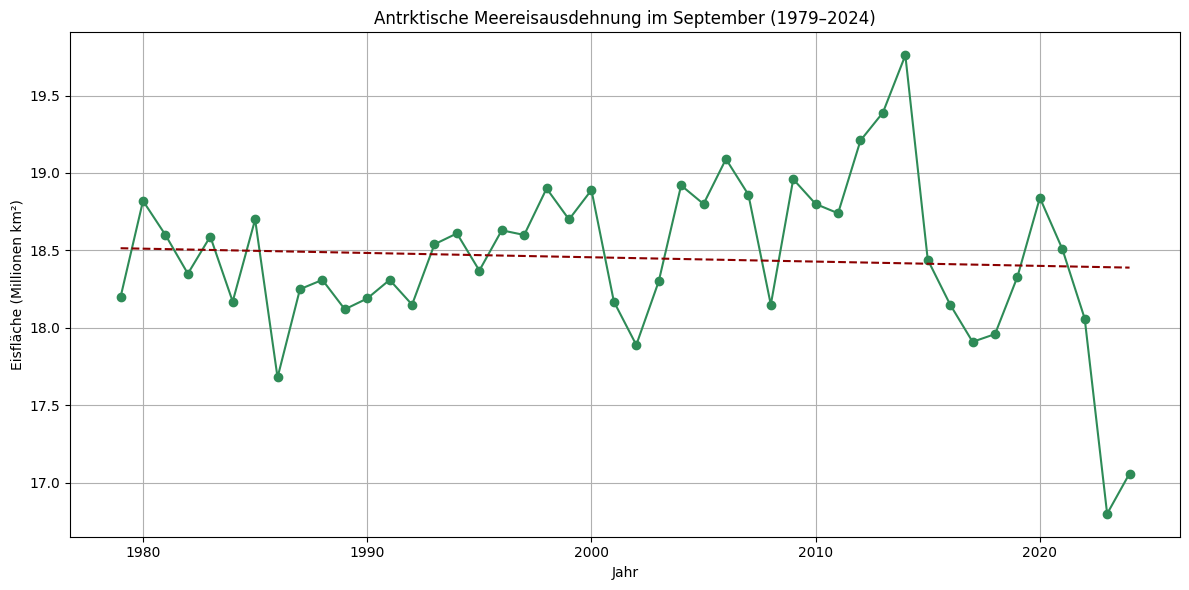

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


file_path = "S_09_extent_v3.0.csv"
df = pd.read_csv(file_path, header=None)


df.columns = ["Year", "Month", "Source", "Region", "Extent", "Area"]


df = df[["Year", "Extent"]].copy()
df["Year"] = pd.to_numeric(df["Year"], errors='coerce')
df["Extent"] = pd.to_numeric(df["Extent"], errors='coerce')


import numpy as np

df = df.dropna(subset=["Year", "Extent"])

z = np.polyfit(df["Year"], df["Extent"], 1)
p = np.poly1d(z)

plt.figure(figsize=(12, 6))
plt.plot(df["Year"], df["Extent"], marker='o', linestyle='-', color='seagreen', label="Meereisausdehnung im September")
plt.plot(df["Year"], p(df["Year"]), linestyle='--', color='darkred', label=f"Trendlinie ({z[0]:.2f} Mio. km²/Jahr)")
plt.title("Antrktische Meereisausdehnung im September (1979–2024)")
plt.xlabel("Jahr")
plt.ylabel("Eisfläche (Millionen km²)")
plt.grid(True)
plt.tight_layout()
plt.show()


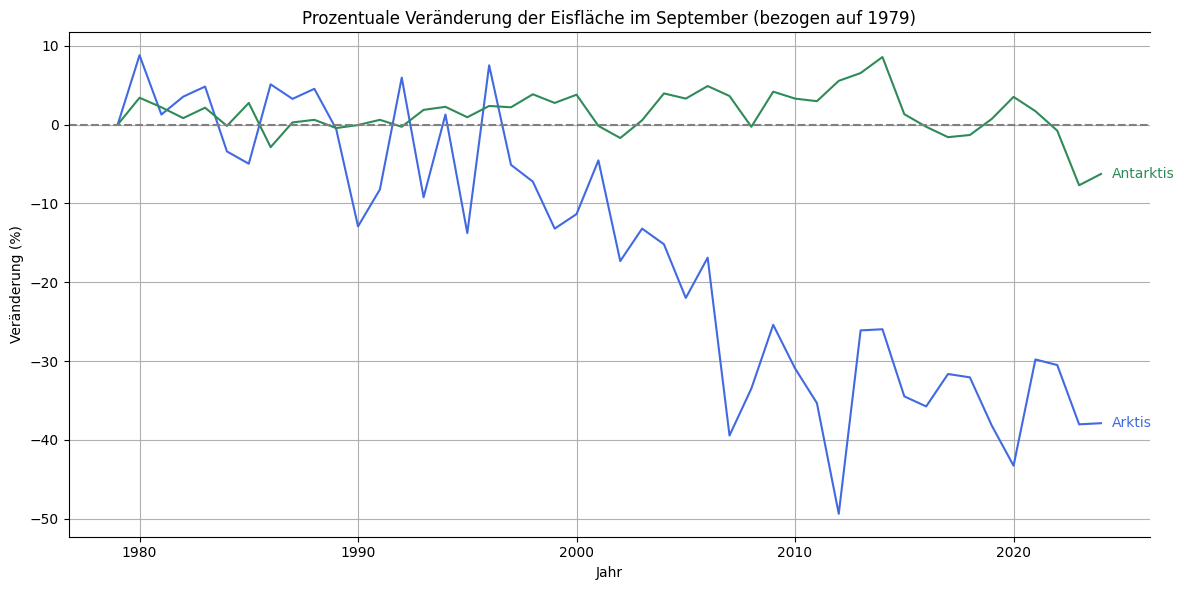

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


arktis_df = pd.read_csv("N_09_extent_v3.0.csv", header=None)
antarktis_df = pd.read_csv("S_09_extent_v3.0.csv", header=None)


columns = ["Year", "Month", "Source", "Region", "Extent", "Area"]
arktis_df.columns = antarktis_df.columns = columns


arktis = arktis_df[["Year", "Extent"]].dropna()
antarktis = antarktis_df[["Year", "Extent"]].dropna()


arktis["Year"] = pd.to_numeric(arktis["Year"], errors="coerce")
arktis["Extent"] = pd.to_numeric(arktis["Extent"], errors="coerce")
antarktis["Year"] = pd.to_numeric(antarktis["Year"], errors="coerce")
antarktis["Extent"] = pd.to_numeric(antarktis["Extent"], errors="coerce")

arktis = arktis.groupby("Year").mean().reset_index()
antarktis = antarktis.groupby("Year").mean().reset_index()

arktis_base = arktis.iloc[0]["Extent"]
antarktis_base = antarktis.iloc[0]["Extent"]
arktis["Change_%"] = (arktis["Extent"] - arktis_base) / arktis_base * 100
antarktis["Change_%"] = (antarktis["Extent"] - antarktis_base) / antarktis_base * 100

plt.figure(figsize=(12, 6))
plt.plot(arktis["Year"], arktis["Change_%"], color="royalblue")
plt.plot(antarktis["Year"], antarktis["Change_%"], color="seagreen")
plt.axhline(0, color='gray', linestyle='--')

plt.text(arktis["Year"].iloc[-1] + 0.5, arktis["Change_%"].iloc[-1], "Arktis", color="royalblue", va='center')
plt.text(antarktis["Year"].iloc[-1] + 0.5, antarktis["Change_%"].iloc[-1], "Antarktis", color="seagreen", va='center')

plt.title("Prozentuale Veränderung der Eisfläche im September (bezogen auf 1979)")
plt.xlabel("Jahr")
plt.ylabel("Veränderung (%)")
plt.grid(True)
plt.tight_layout()
plt.gca().spines['right'].set_visible(False)  
plt.show()


Das arktische Meereis im September ist seit 1979 um rund 40 % geschrumpft. Die Antarktis war lange stabil, fällt aber seit etwa 2016 deutlich ab.

## Extremwetter

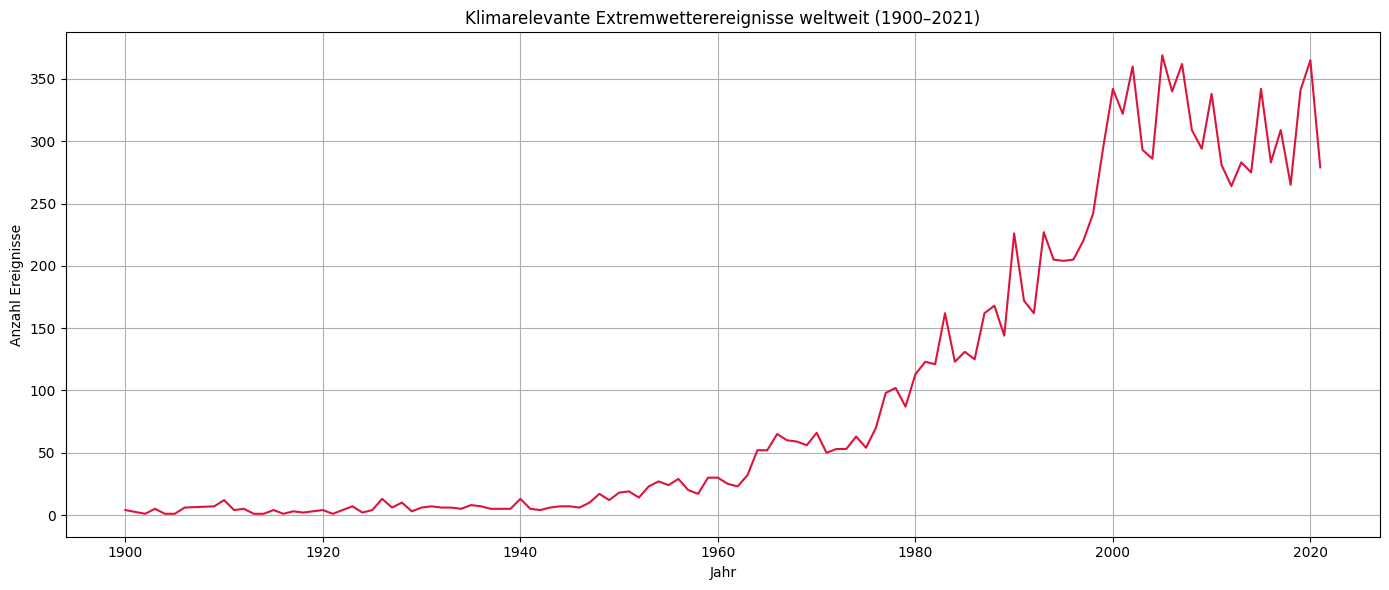

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("1900_2021_DISASTERS.xlsx - emdat data.csv")

klimarelevante_typen = [
    "Flood",              
    "Storm",              
    "Drought",            
    "Extreme temperature",
    "Wildfire",           
    "Landslide"           
]

df_klima = df[df["Disaster Type"].isin(klimarelevante_typen)]

events_per_year = df_klima.groupby("Year").size()

plt.figure(figsize=(14, 6))
plt.plot(events_per_year.index, events_per_year.values, color="crimson")
plt.title("Klimarelevante Extremwetterereignisse weltweit (1900–2021)")
plt.xlabel("Jahr")
plt.ylabel("Anzahl Ereignisse")
plt.grid(True)
plt.tight_layout()
plt.show()


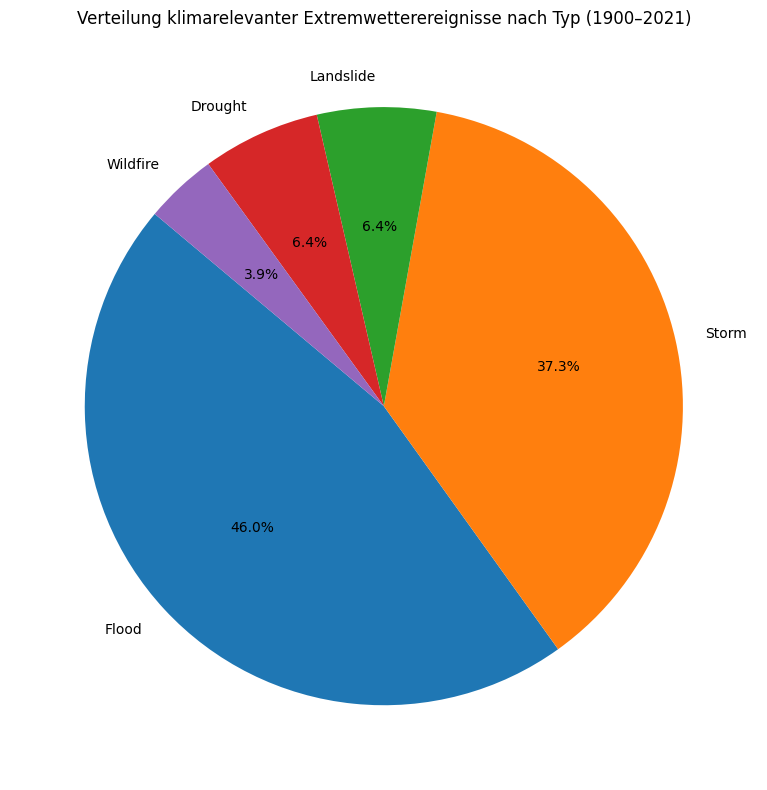

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("1900_2021_DISASTERS.xlsx - emdat data.csv")

klimarelevante_typen = [
    "Flood",
    "Storm",
    "Drought",
    "Extreme temperature",
    "Wildfire",
    "Landslide"
]

df_klima = df[df["Disaster Type"].isin(klimarelevante_typen)]

event_type_counts = df_klima["Disaster Type"].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(event_type_counts,
        labels=event_type_counts.index,
        autopct="%1.1f%%",
        startangle=140)
plt.title("Verteilung klimarelevanter Extremwetterereignisse nach Typ (1900–2021)")
plt.tight_layout()
plt.show()


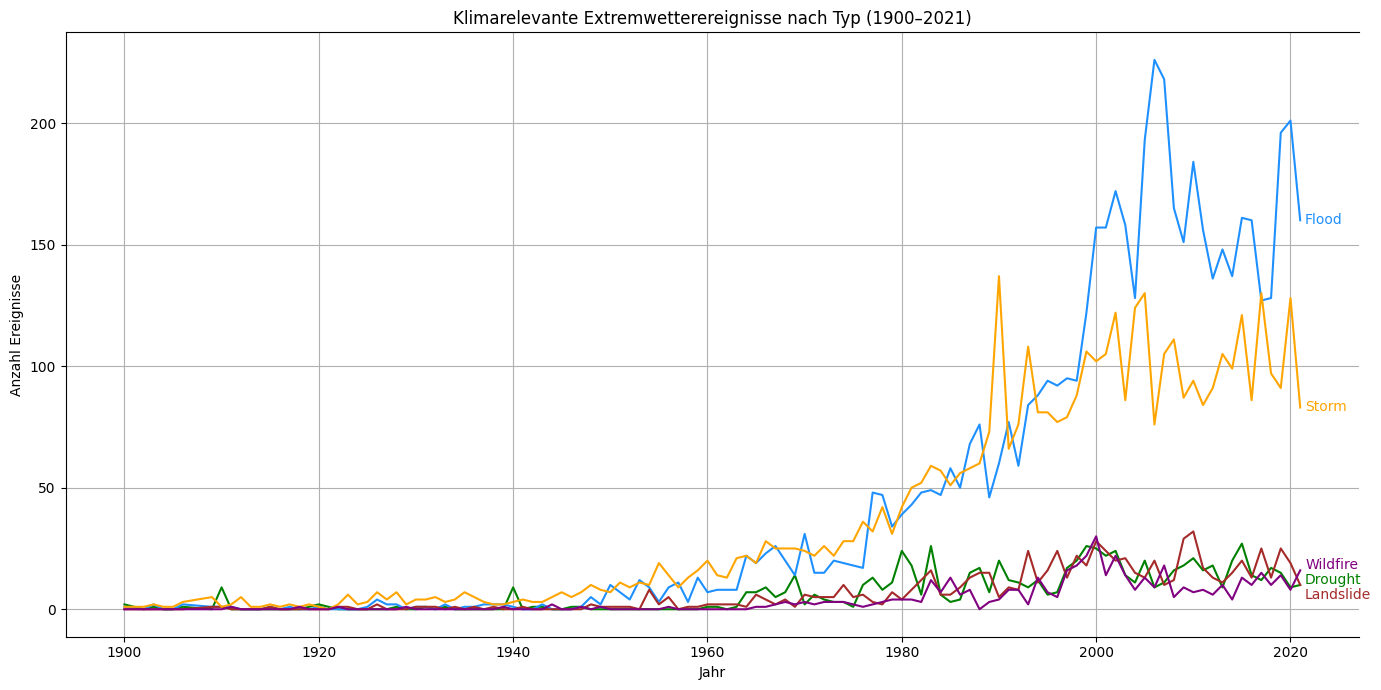

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("1900_2021_DISASTERS.xlsx - emdat data.csv")

farben = {
    "Flood": "dodgerblue",
    "Storm": "orange",
    "Drought": "green",
    "Extreme temperature": "red",
    "Wildfire": "purple",
    "Landslide": "brown"
}

events_by_year_type = df_klima.groupby(["Year", "Disaster Type"]).size().unstack(fill_value=0)

plt.figure(figsize=(14, 7))

label_offsets = {
    "Flood": 0,
    "Storm": 0,
    "Drought": 2,
    "Extreme temperature": -2,
    "Wildfire": 2,
    "Landslide": -4
}

for typ in events_by_year_type.columns:
    plt.plot(events_by_year_type.index, events_by_year_type[typ],
             label=typ, color=farben.get(typ, "gray"))

    last_year = events_by_year_type.index[-1]
    last_value = events_by_year_type[typ].iloc[-1]
    offset = label_offsets.get(typ, 0)

    plt.text(last_year + 0.5, last_value + offset, typ,
             color=farben.get(typ, "gray"), fontsize=10,
             va='center')

plt.title("Klimarelevante Extremwetterereignisse nach Typ (1900–2021)")
plt.xlabel("Jahr")
plt.ylabel("Anzahl Ereignisse")
plt.grid(True)

plt.gca().spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


Die Zahl der erfassten klimarelevanten Extremwetterereignisse ist seit 1960 stark gestiegen, vor allem Überschwemmungen
und Stürme. Ein Teil des Anstiegs geht auch auf bessere Erfassung zurück.

## Krankheiten

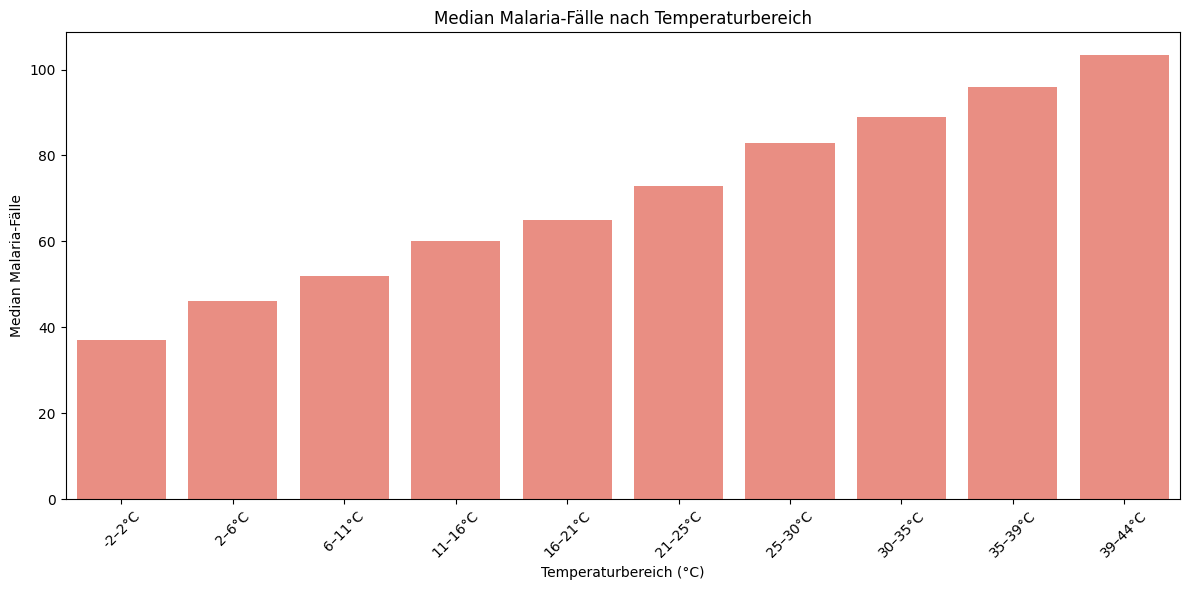

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("climate_disease_dataset.csv")

bins = pd.cut(df["avg_temp_c"], bins=10)
rounded_labels = [f"{int(interval.left)}–{int(interval.right)}°C" for interval in bins.cat.categories]
df["temp_group"] = pd.cut(df["avg_temp_c"], bins=10, labels=rounded_labels)

grouped_malaria = df.groupby("temp_group")["malaria_cases"].median().reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=grouped_malaria, x="temp_group", y="malaria_cases", color="salmon")
plt.title("Median Malaria-Fälle nach Temperaturbereich")
plt.xlabel("Temperaturbereich (°C)")
plt.ylabel("Median Malaria-Fälle")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Je wärmer es ist, desto mehr Malaria-Fälle treten im Median auf. Wärmere Regionen bieten den übertragenden Mücken bessere Bedingungen.

---
# Fazit

Die Daten zeigen deutlich: Die Temperatur steigt, und sie steigt im Gleichschritt mit den CO2-Emissionen. Die Emissionen
wachsen mit Wirtschaft, Bevölkerung und Verkehr. Verantwortlich sind vor allem große Volkswirtschaften, pro Kopf aber
auch reiche Golfstaaten. Die Folgen sind bereits messbar, vom Meeresspiegel über das Meereis bis zu Extremwetter.